# Multimodal Product Classification
> Multi-class product categorization from text and image embeddings

This notebook classifies BestBuy.com products into 16 categories using both their text descriptions and their images. Each modality is converted into a fixed-size embedding with a pre-trained model (`all-MiniLM-L6-v2` for text, `ConvNextV2-tiny` for images), and these embeddings are used as features for two families of models: classical machine learning classifiers and a Keras multi-layer perceptron (MLP). Each family is trained on text-only, image-only, and combined (early fusion) features to measure how much each modality contributes.

In [1]:
import sys

IN_COLAB = "google.colab" in sys.modules
IN_COLAB

False

In [2]:
# Check if the O.S is Mx Mac
import platform
IN_MAC = platform.system() == "Darwin"
IN_MAC

False

In [3]:
if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")

In [4]:
if IN_COLAB:
    # Put here the full path to the folder having your Sprint project code
    # e.g. "/content/drive/MyDrive/assignment"
    ROOT_DIR = "/content/drive/MyDrive/assignment"
    %cd $ROOT_DIR

In [5]:
# Include automatic reload of files
%load_ext autoreload
%autoreload 2

### Environment setup

The cells below install dependencies only when running in Google Colab or on an Apple Silicon Mac. In a local environment, install the packages from `requirements.txt` instead.

In [6]:
if IN_COLAB:
    # This will make sure you have installed all the proper dependencies
    # Instal dependencies
    !pip install -r requirements.txt
    # We can access to GPUs in Colab, so install GPU version of tensorflow
    !pip install tensorflow-gpu==2.10.

In [7]:
if IN_MAC:
    # To access the GPU in Mx Mac, we need to install the Metal Plugin
    !pip install tensorflow-macos==2.5.0
    !pip install tensorflow-metal==0.1.2

## 1. Overview

**Objective:** Predict the category of a BestBuy.com product from its textual description and its image.

**Data:** A preprocessed product table (`processed_products_with_images.csv`) derived from two raw JSON files:
- `products.json`: product attributes such as name, description, and price.
- `categories.json`: the hierarchical category tree.

Product images are stored separately at 224 x 224 pixels ([download](https://drive.google.com/file/d/14s2aDNTEWse86cWyLhvVIKmob6EbQrm_/view?usp=sharing)).

**Evaluation:** Accuracy and macro-averaged F1 score on a 30% held-out test set. Macro F1 is reported alongside accuracy because the class distribution is highly imbalanced.

**Pipeline:**
1. **Exploratory data analysis** of the product table and images.
2. **Embedding generation** for product images and descriptions.
3. **Model training** with classical ML classifiers and an MLP on text, image, and combined features.
4. **Evaluation** of each model, including per-class performance.

In [8]:
### IMPORTS ###
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from src.utils import ImageDownloader
from src.vision_embeddings_tf import get_embeddings_df
from src.nlp_models import HuggingFaceEmbeddings
from src.nlp_models import GPT
from src.utils import preprocess_data, train_test_split_and_feature_extraction
import os

from src.classifiers_classic_ml import train_and_evaluate_model as train_classic

from src.classifiers_mlp import MultimodalDataset
from sklearn.preprocessing import LabelEncoder
from src.classifiers_mlp import train_mlp

### Data sources

The project uses `processed_products_with_images.csv` (placed in `data/`) and the product images (placed in `data/images/`). The images were downloaded at 224 x 224 pixels with the `ImageDownloader` class in `src/utils.py`. To re-download them at a different resolution, the following snippet can be used:

```python
# Load the data:
CSV_PATH = 'data/processed_products.csv'
df = pd.read_csv(CSV_PATH)

# Download the images and add the image paths to the dataframe:
DIR='data/images/'
SHAPE=(224, 224)
OVERWRITE=False
OUTPUT_CSV='data/processed_products_with_images.csv'

# Instantiate the ImageDownloader class
image_downloader = ImageDownloader(image_dir=DIR, image_size=SHAPE, overwrite=OVERWRITE)

# Download images and get the updated DataFrame
updated_df = image_downloader.download_images(df)

# Save the updated DataFrame
updated_df.to_csv(OUTPUT_CSV, index=False)
```

#### Dataset basics

A first look at the product table and a random sample of product images.

In [9]:
# See the data
df = pd.read_csv('data/processed_products_with_images.csv')
df.head()

,sku,name,description,image,type,price,shipping,manufacturer,class_id,sub_class1_id,num_classes,image_path
0,43900,Duracell - AAA Batteries (4-Pack),Compatible with select electronic devices; AAA...,http://img.bbystatic.com/BestBuy_US/images/pro...,HardGood,5.49,5.49,Duracell,pcmcat312300050015,pcmcat248700050021,2,data/images/43900.jpg
1,48530,Duracell - AA 1.5V CopperTop Batteries (4-Pack),Long-lasting energy; DURALOCK Power Preserve t...,http://img.bbystatic.com/BestBuy_US/images/pro...,HardGood,5.49,5.49,Duracell,pcmcat312300050015,pcmcat248700050021,2,data/images/48530.jpg
2,127687,Duracell - AA Batteries (8-Pack),Compatible with select electronic devices; AA ...,http://img.bbystatic.com/BestBuy_US/images/pro...,HardGood,7.49,5.49,Duracell,pcmcat312300050015,pcmcat248700050021,2,data/images/127687.jpg
3,150115,Energizer - MAX Batteries AA (4-Pack),4-pack AA alkaline batteries; battery tester i...,http://img.bbystatic.com/BestBuy_US/images/pro...,HardGood,4.99,5.49,Energizer,pcmcat312300050015,pcmcat248700050021,2,data/images/150115.jpg
4,185230,Duracell - C Batteries (4-Pack),Compatible with select electronic devices; C s...,http://img.bbystatic.com/BestBuy_US/images/pro...,HardGood,8.99,5.49,Duracell,pcmcat312300050015,pcmcat248700050021,2,data/images/185230.jpg


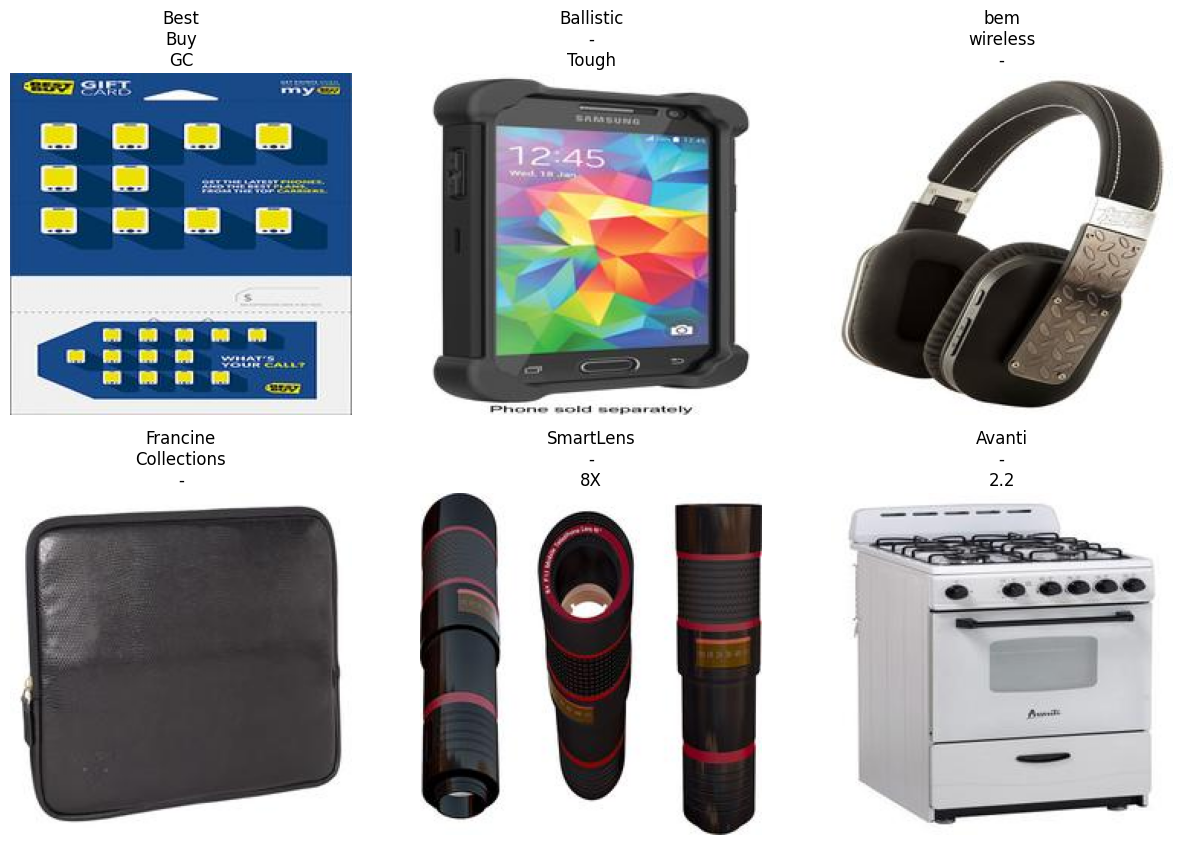

In [14]:
# Display 6 random images from the dataset
fig, ax = plt.subplots(2, 3, figsize=(15, 10))
for i in range(2):
    for j in range(3):
        # Get a random index
        idx = df.sample().index[0]
        # Read the image
        img = mpimg.imread(df.loc[idx, 'image_path'])
        # Display the image
        ax[i, j].imshow(img)
        # Set the title
        ax[i, j].set_title('\n'.join(df.loc[idx, 'name'].split()[:3]))
        ax[i, j].axis('off')


## 2. Embedding generation

Text and images are high-dimensional and structurally very different, so neither can be fed directly into a single classifier. Each modality is therefore mapped into a dense, fixed-size vector using a pre-trained model. These embeddings act as learned feature extractors and give both modalities a homogeneous numeric representation that downstream models can consume.

### 2.1 Image embeddings

Image embeddings are extracted with `get_embeddings_df` from `src/vision_embeddings_tf.py`, which runs every image through a pre-trained backbone (TensorFlow / Hugging Face Transformers) and returns one fixed-size vector per image.

```python
get_embeddings_df(
    batch_size=32,
    path='data/images',
    dataset_name='',
    backbone='convnextv2_tiny',
    directory='Embeddings'
)
```

**Supported backbones:**
- ResNet: `resnet50`, `resnet101`
- DenseNet: `densenet121`, `densenet169`
- Inception: `inception_v3`
- ConvNextV2: `convnextv2_tiny`, `convnextv2_base`, `convnextv2_large`
- Swin: `swin_tiny`, `swin_small`, `swin_base`
- ViT: `vit_base`, `vit_large`
- CLIP: `clip_base`, `clip_large`

ConvNextV2 variants are loaded from [Hugging Face](https://huggingface.co/docs/transformers/en/model_doc/convnextv2#transformers.TFConvNextV2Model), and the CNN backbones such as ResNet50 from [tensorflow.keras.applications](https://www.tensorflow.org/api_docs/python/tf/keras/applications). The `convnextv2_tiny` embeddings are used for all models below.

**Output:** `Embeddings_{model_name}.csv`, containing the image name and one column per embedding dimension.

In [10]:
batch_size = 32
path = 'data/images'
dataset = ''
backbone = 'convnextv2_tiny'
out_dir = 'Embeddings_test'

get_embeddings_df(batch_size=batch_size, path=path, dataset_name=dataset, backbone=backbone, directory=out_dir)

Skipping 3122677.jpg due to error
Skipping 3459533.jpg due to error
Skipping 5092130.jpg due to error
Skipping 5907298.jpg due to error
Skipping 8349075.jpg due to error
Skipping 9373867.jpg due to error
Skipping 9744871.jpg due to error


Some weights of the PyTorch model were not used when initializing the TF 2.0 model TFConvNextV2Model: ['classifier.weight', 'classifier.bias']
- This IS expected if you are initializing TFConvNextV2Model from a PyTorch model trained on another task or with another architecture (e.g. initializing a TFBertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFConvNextV2Model from a PyTorch model that you expect to be exactly identical (e.g. initializing a TFBertForSequenceClassification model from a BertForSequenceClassification model).
All the weights of TFConvNextV2Model were initialized from the PyTorch model.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFConvNextV2Model for predictions without further training.


1/1 [==============================] - 41s 41s/step
Batch 10/1553 done
1/1 [==============================] - 36s 36s/step
Batch 20/1553 done
1/1 [==============================] - 40s 40s/step
Batch 30/1553 done
1/1 [==============================] - 53s 53s/step
Batch 40/1553 done
1/1 [==============================] - 42s 42s/step
Batch 50/1553 done
1/1 [==============================] - 38s 38s/step
Batch 60/1553 done
1/1 [==============================] - 40s 40s/step
Batch 70/1553 done
1/1 [==============================] - 45s 45s/step
Batch 80/1553 done
1/1 [==============================] - 45s 45s/step
Batch 90/1553 done
1/1 [==============================] - 41s 41s/step
Batch 100/1553 done
1/1 [==============================] - 41s 41s/step
Batch 110/1553 done
1/1 [==============================] - 41s 41s/step
Batch 120/1553 done
1/1 [==============================] - 42s 42s/step
Batch 130/1553 done
1/1 [==============================] - 42s 42s/step
Batch 140/1553 done
1

### 2.2 Text embeddings

Product descriptions are embedded with a pre-trained transformer through the `HuggingFaceEmbeddings` class in `src/nlp_models.py`. A `GPT` class is also available to generate embeddings with OpenAI's embedding models.

#### Hugging Face embeddings

`HuggingFaceEmbeddings` takes the following parameters:
- `model_name`: name of the pre-trained transformer model.
- `device`: compute device (`'cpu'`, `'cuda'`, or `'mps'`).
- `path`: path to the CSV file containing the text data.

Its `get_embedding_df(column, directory, file)` method embeds the given text `column` and saves the result as `file` inside `directory`.

```python
# Usage example for BERT:
device = 'mps'
model = HuggingFaceEmbeddings(model_name='bert-base-uncased', device=device)

model.path = 'data/processed_products_with_images.csv'
column = 'description'
directory = 'Embeddings/'
file = 'text_embeddings_bert.csv'

model.get_embedding_df(column, directory, file)
```

**Output:** A CSV file (e.g. `Embeddings/text_embeddings_bert.csv`) containing the product metadata and the embedding of each description, stored as a list in a single `embeddings` column. The list is expanded into one column per dimension in the merging step.

The model used in this notebook is `sentence-transformers/all-MiniLM-L6-v2`.

In [ ]:
# Usage example for all-MiniLM-L6-v2:
device = 'cpu' # Set to 'cuda' if you have a GPU, 'cpu' otherwise
model = HuggingFaceEmbeddings(model_name='sentence-transformers/all-MiniLM-L6-v2', device=device)

model.path = 'data/processed_products_with_images.csv' # This is the output of the previous step
column = 'description'
directory = 'Embeddings/'
file = 'text_embeddings_minilm.csv'

model.get_embedding_df(column, directory, file)

Using device: cpu
Model moved to device: cpu
Model: sentence-transformers/all-MiniLM-L6-v2
Embeddings saved to Embeddings/text_embeddings_minilm.csv


#### OpenAI embeddings (optional)

The `GPT` class generates embeddings through the OpenAI API, using any of the available [embedding models](https://platform.openai.com/docs/models/embeddings). It was not used for the results in this notebook.

```python
# Choose your model from the list of models:
model = GPT(embedding_model='text-embedding-3-small')

model.path = 'data/processed_products_with_images.csv'
column = 'description'
directory = 'Embeddings/'
file = 'text_embeddings.csv'

model.get_embedding_df(column, directory, file)
```

In [12]:
# Optional: Use OpenAI's API to get the embeddings


### 2.3 Merging embeddings

The text and image embeddings are joined into a single training table with `preprocess_data` from `src/utils.py`, which takes the following parameters:
- `text_data`: text embeddings dataframe.
- `image_data`: image embeddings dataframe.
- `text_id`: column identifying each product's image in the text table.
- `image_id`: column identifying each image in the image table.
- `embeddings_col`: name of the column holding the text embedding lists.

```python
preprocess_data(text_data, image_data, text_id="image_id", image_id="ImageName", embeddings_col = 'embeddings')
```

**Output:** A dataframe with the product IDs, metadata, and category, plus `n + m` embedding columns named `text_0, ..., text_n` and `image_0, ..., image_m`, where `n` and `m` are the text and image embedding sizes.

In [14]:
# Merge the embeddings
PATH = 'Embeddings/'
text_path = 'text_embeddings_minilm.csv'
images_path = 'Embeddings_convnextv2_tiny.csv'

# Read unimodal data
text = pd.read_csv(os.path.join(PATH, text_path))

images = pd.read_csv(os.path.join(PATH, images_path))

# Merge and preprocess the datasets
df = preprocess_data(text, images, "image_path", "ImageName")

df.to_csv(os.path.join(PATH, 'embeddings_minilm.csv'), index=False)

## 3. Model training

Two modeling approaches are compared:
1. **Classical machine learning** classifiers trained directly on the embeddings.
2. **A multi-layer perceptron (MLP)** trained on the same embeddings.

Both approaches use the same 70/30 train/test split so that their results are directly comparable.

### 3.1 Dataset preparation

The merged table is split into training and test sets with `train_test_split_and_feature_extraction` (a wrapper around scikit-learn's `train_test_split`), which also returns the text, image, and label column names.

Three feature sets are evaluated for each approach:
- **Text only:** text embedding columns.
- **Image only:** image embedding columns.
- **Multimodal:** text and image embedding columns combined.

In [15]:
# Read the data:
PATH = 'Embeddings/'
df = pd.read_csv(os.path.join(PATH, 'embeddings_minilm.csv'))

# Split the data into train and test sets and extract the features
train_df, test_df, text_columns, image_columns, label_columns = train_test_split_and_feature_extraction(df)

### 3.2 Classical ML models

`train_and_evaluate_model` (imported as `train_classic`) trains and evaluates five classifiers on a given feature set: Random Forest, Logistic Regression, Decision Tree, XGBoost, and LightGBM. A classification report and confusion matrix are produced for each.

In [12]:
### Labels
y_train = train_df[label_columns].values
y_test = test_df[label_columns].values

Category labels are encoded as integers, since XGBoost and LightGBM require numeric targets. The original string labels are kept for readable reports.

In [11]:
from sklearn.preprocessing import LabelEncoder

# Save original labels for visualization
y_train_original = train_df[label_columns[0]].values
y_test_original = test_df[label_columns[0]].values

# Encode to numbers
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(train_df[label_columns[0]].values)
y_test = label_encoder.transform(test_df[label_columns[0]].values)


#### Text features

####################  Random Forest  ####################


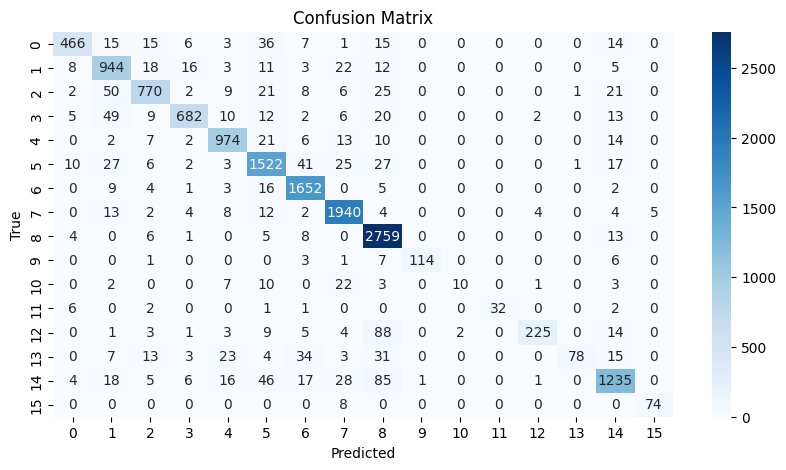

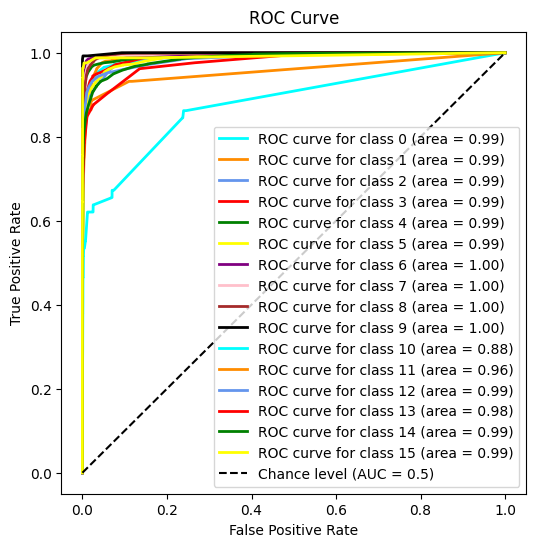

              precision    recall  f1-score   support

           0       0.92      0.81      0.86       578
           1       0.83      0.91      0.87      1042
           2       0.89      0.84      0.87       915
           3       0.94      0.84      0.89       810
           4       0.92      0.93      0.92      1049
           5       0.88      0.91      0.89      1681
           6       0.92      0.98      0.95      1692
           7       0.93      0.97      0.95      1998
           8       0.89      0.99      0.94      2796
           9       0.99      0.86      0.92       132
          10       0.83      0.17      0.29        58
          11       1.00      0.73      0.84        44
          12       0.97      0.63      0.77       355
          13       0.97      0.37      0.54       211
          14       0.90      0.84      0.87      1462
          15       0.94      0.90      0.92        82

    accuracy                           0.90     14905
   macro avg       0.92   

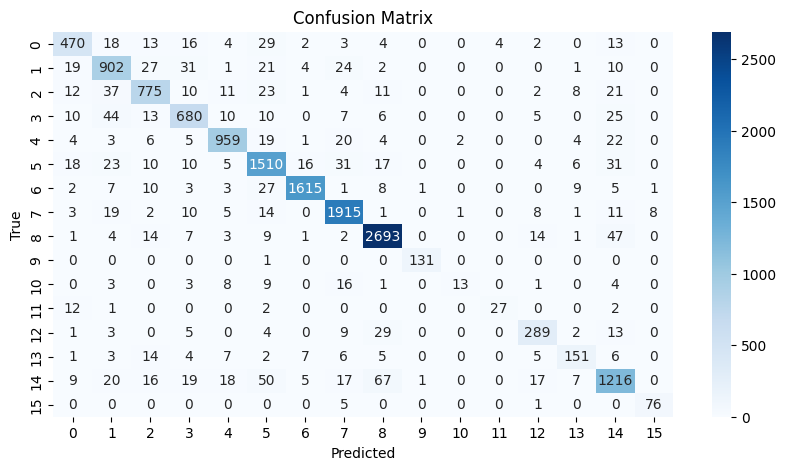

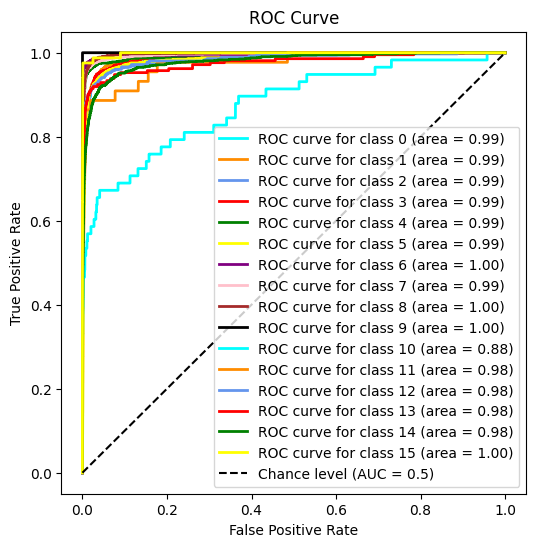

              precision    recall  f1-score   support

           0       0.84      0.81      0.82       578
           1       0.83      0.87      0.85      1042
           2       0.86      0.85      0.85       915
           3       0.85      0.84      0.84       810
           4       0.93      0.91      0.92      1049
           5       0.87      0.90      0.89      1681
           6       0.98      0.95      0.97      1692
           7       0.93      0.96      0.94      1998
           8       0.95      0.96      0.95      2796
           9       0.98      0.99      0.99       132
          10       0.81      0.22      0.35        58
          11       0.87      0.61      0.72        44
          12       0.83      0.81      0.82       355
          13       0.79      0.72      0.75       211
          14       0.85      0.83      0.84      1462
          15       0.89      0.93      0.91        82

    accuracy                           0.90     14905
   macro avg       0.88   

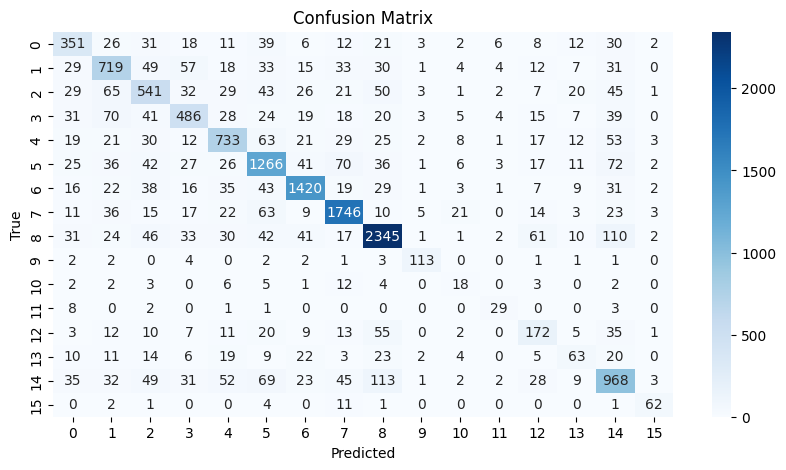

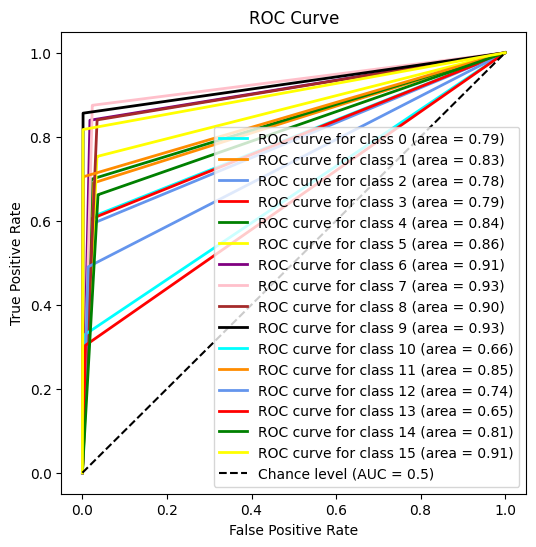

              precision    recall  f1-score   support

           0       0.58      0.61      0.59       578
           1       0.67      0.69      0.68      1042
           2       0.59      0.59      0.59       915
           3       0.65      0.60      0.62       810
           4       0.72      0.70      0.71      1049
           5       0.73      0.75      0.74      1681
           6       0.86      0.84      0.85      1692
           7       0.85      0.87      0.86      1998
           8       0.85      0.84      0.84      2796
           9       0.83      0.86      0.84       132
          10       0.23      0.31      0.27        58
          11       0.54      0.66      0.59        44
          12       0.47      0.48      0.48       355
          13       0.37      0.30      0.33       211
          14       0.66      0.66      0.66      1462
          15       0.77      0.76      0.76        82

    accuracy                           0.74     14905
   macro avg       0.65   

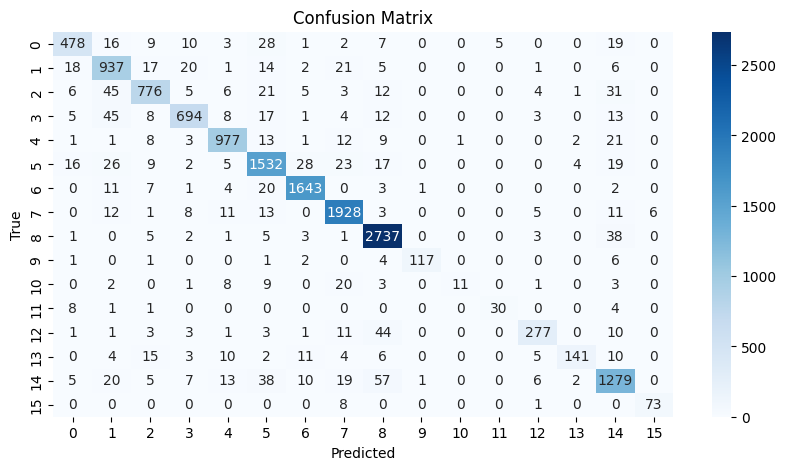

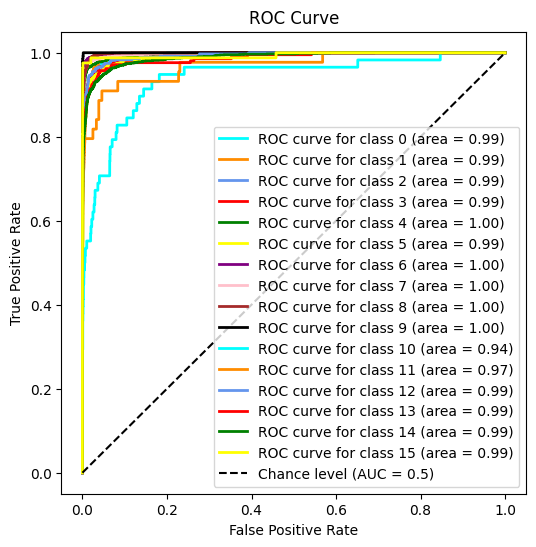

              precision    recall  f1-score   support

           0       0.89      0.83      0.86       578
           1       0.84      0.90      0.87      1042
           2       0.90      0.85      0.87       915
           3       0.91      0.86      0.88       810
           4       0.93      0.93      0.93      1049
           5       0.89      0.91      0.90      1681
           6       0.96      0.97      0.97      1692
           7       0.94      0.96      0.95      1998
           8       0.94      0.98      0.96      2796
           9       0.98      0.89      0.93       132
          10       0.92      0.19      0.31        58
          11       0.86      0.68      0.76        44
          12       0.91      0.78      0.84       355
          13       0.94      0.67      0.78       211
          14       0.87      0.87      0.87      1462
          15       0.92      0.89      0.91        82

    accuracy                           0.91     14905
   macro avg       0.91   

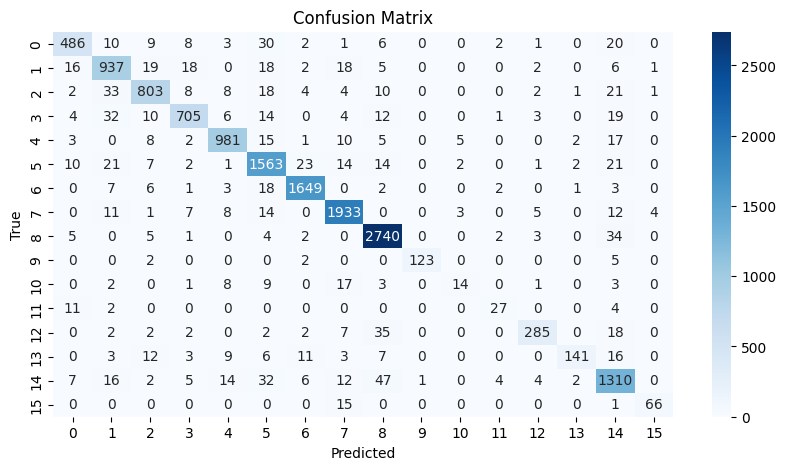

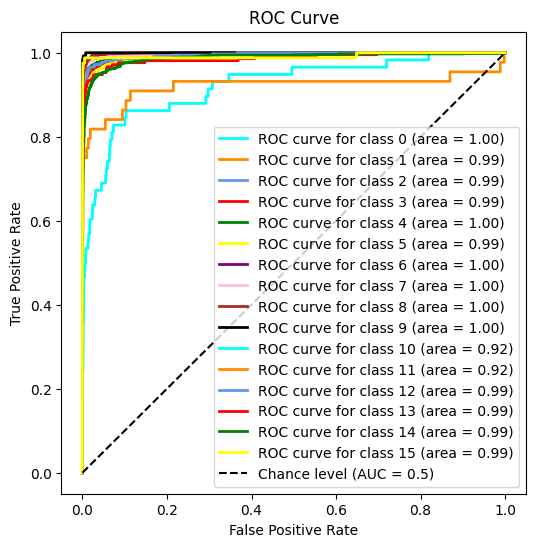

              precision    recall  f1-score   support

           0       0.89      0.84      0.87       578
           1       0.87      0.90      0.88      1042
           2       0.91      0.88      0.89       915
           3       0.92      0.87      0.90       810
           4       0.94      0.94      0.94      1049
           5       0.90      0.93      0.91      1681
           6       0.97      0.97      0.97      1692
           7       0.95      0.97      0.96      1998
           8       0.95      0.98      0.96      2796
           9       0.99      0.93      0.96       132
          10       0.58      0.24      0.34        58
          11       0.71      0.61      0.66        44
          12       0.93      0.80      0.86       355
          13       0.95      0.67      0.78       211
          14       0.87      0.90      0.88      1462
          15       0.92      0.80      0.86        82

    accuracy                           0.92     14905
   macro avg       0.89   

In [30]:
# Combine text columns to form the feature set
X_train = train_df[text_columns].values
X_test = test_df[text_columns].values

# Train and evaluate models
trained_models = train_classic(X_train, X_test, y_train, y_test, class_names=y_test_original)

#### Image features

####################  Random Forest  ####################


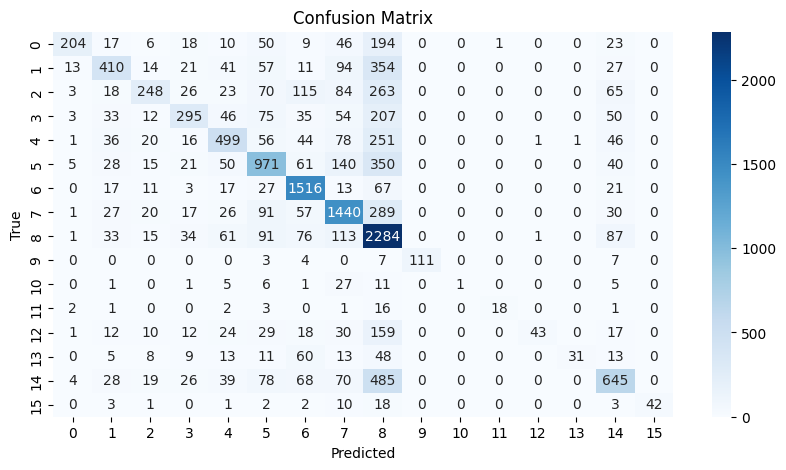

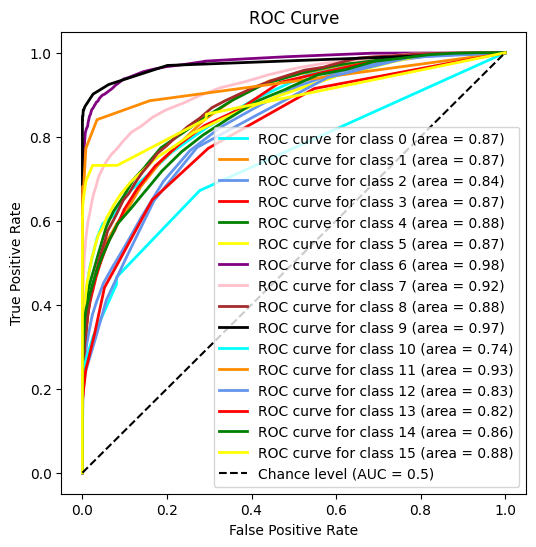

              precision    recall  f1-score   support

           0       0.86      0.35      0.50       578
           1       0.61      0.39      0.48      1042
           2       0.62      0.27      0.38       915
           3       0.59      0.36      0.45       810
           4       0.58      0.48      0.52      1049
           5       0.60      0.58      0.59      1681
           6       0.73      0.90      0.80      1692
           7       0.65      0.72      0.68      1998
           8       0.46      0.82      0.59      2796
           9       1.00      0.84      0.91       132
          10       1.00      0.02      0.03        58
          11       0.95      0.41      0.57        44
          12       0.96      0.12      0.22       355
          13       0.97      0.15      0.26       211
          14       0.60      0.44      0.51      1462
          15       1.00      0.51      0.68        82

    accuracy                           0.59     14905
   macro avg       0.76   

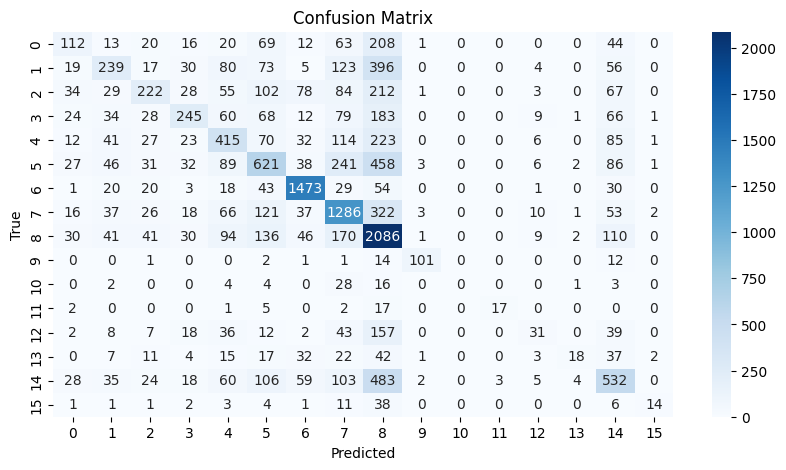

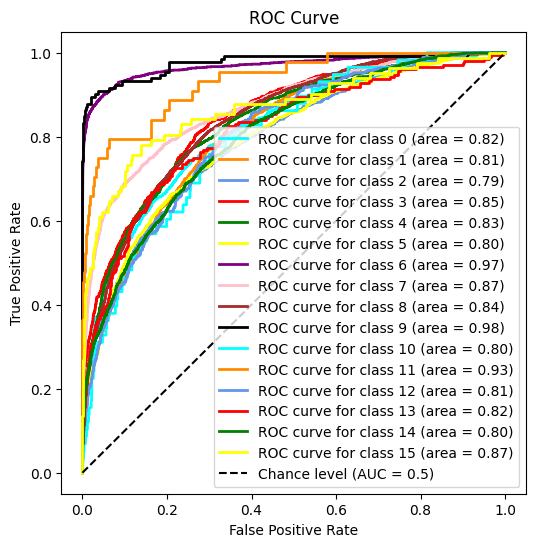

              precision    recall  f1-score   support

           0       0.36      0.19      0.25       578
           1       0.43      0.23      0.30      1042
           2       0.47      0.24      0.32       915
           3       0.52      0.30      0.38       810
           4       0.41      0.40      0.40      1049
           5       0.43      0.37      0.40      1681
           6       0.81      0.87      0.84      1692
           7       0.54      0.64      0.58      1998
           8       0.42      0.75      0.54      2796
           9       0.89      0.77      0.82       132
          10       0.00      0.00      0.00        58
          11       0.85      0.39      0.53        44
          12       0.36      0.09      0.14       355
          13       0.62      0.09      0.15       211
          14       0.43      0.36      0.40      1462
          15       0.67      0.17      0.27        82

    accuracy                           0.50     14905
   macro avg       0.51   

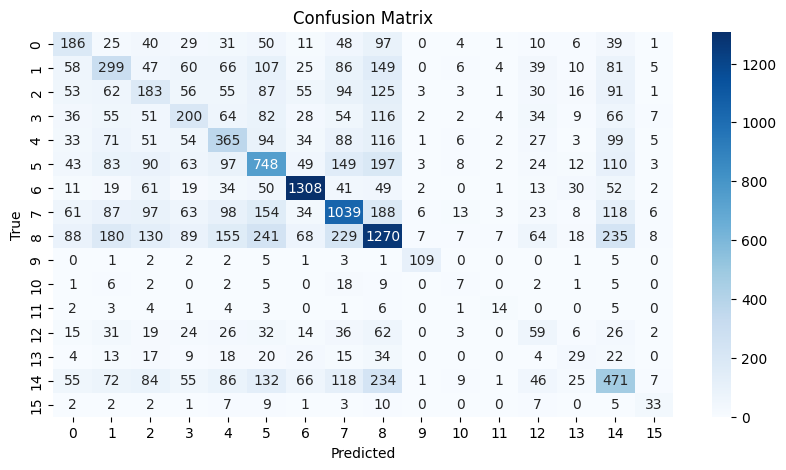

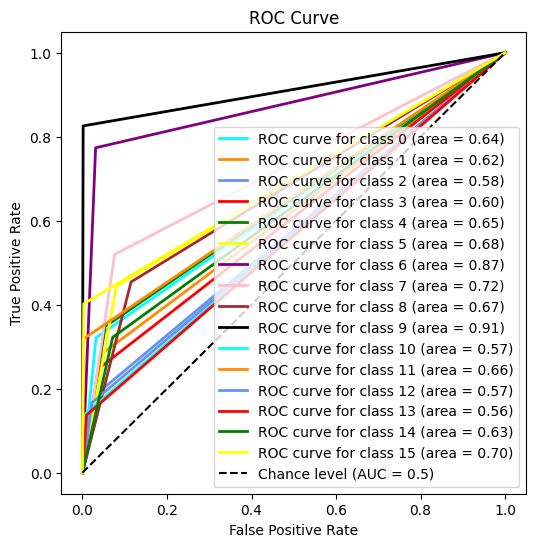

              precision    recall  f1-score   support

           0       0.29      0.32      0.30       578
           1       0.30      0.29      0.29      1042
           2       0.21      0.20      0.20       915
           3       0.28      0.25      0.26       810
           4       0.33      0.35      0.34      1049
           5       0.41      0.44      0.43      1681
           6       0.76      0.77      0.77      1692
           7       0.51      0.52      0.52      1998
           8       0.48      0.45      0.47      2796
           9       0.81      0.83      0.82       132
          10       0.10      0.12      0.11        58
          11       0.35      0.32      0.33        44
          12       0.15      0.17      0.16       355
          13       0.17      0.14      0.15       211
          14       0.33      0.32      0.33      1462
          15       0.41      0.40      0.41        82

    accuracy                           0.42     14905
   macro avg       0.37   

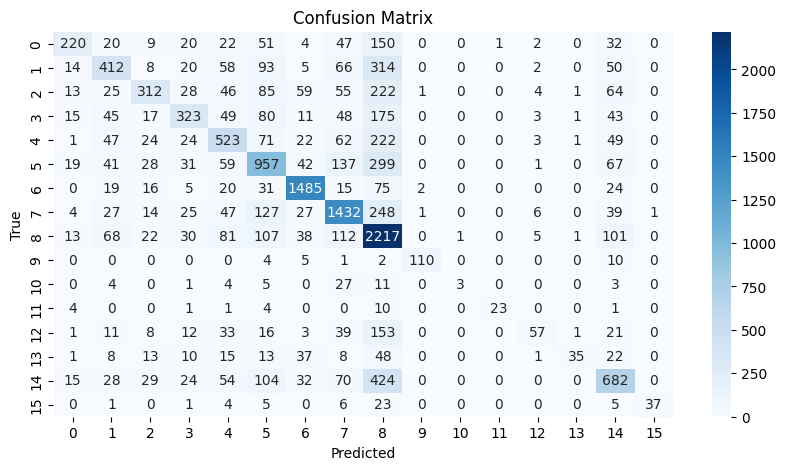

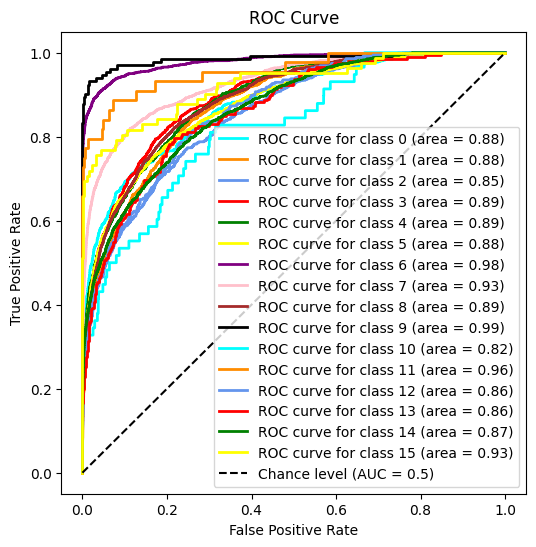

              precision    recall  f1-score   support

           0       0.69      0.38      0.49       578
           1       0.54      0.40      0.46      1042
           2       0.62      0.34      0.44       915
           3       0.58      0.40      0.47       810
           4       0.51      0.50      0.51      1049
           5       0.55      0.57      0.56      1681
           6       0.84      0.88      0.86      1692
           7       0.67      0.72      0.69      1998
           8       0.48      0.79      0.60      2796
           9       0.96      0.83      0.89       132
          10       0.75      0.05      0.10        58
          11       0.96      0.52      0.68        44
          12       0.68      0.16      0.26       355
          13       0.88      0.17      0.28       211
          14       0.56      0.47      0.51      1462
          15       0.97      0.45      0.62        82

    accuracy                           0.59     14905
   macro avg       0.70   

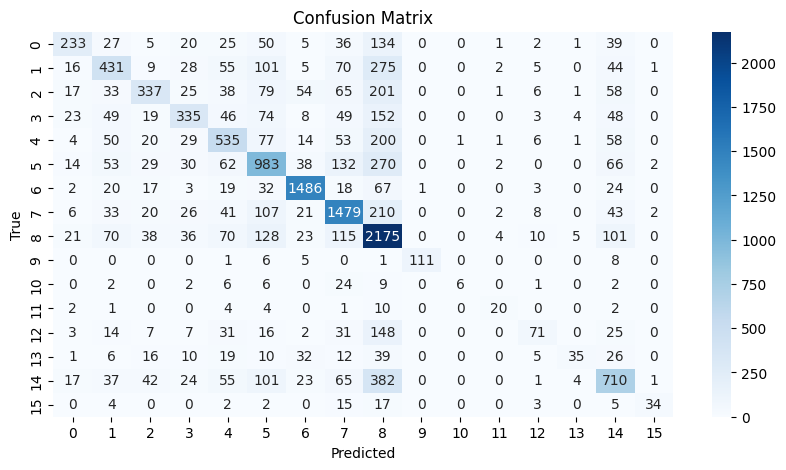

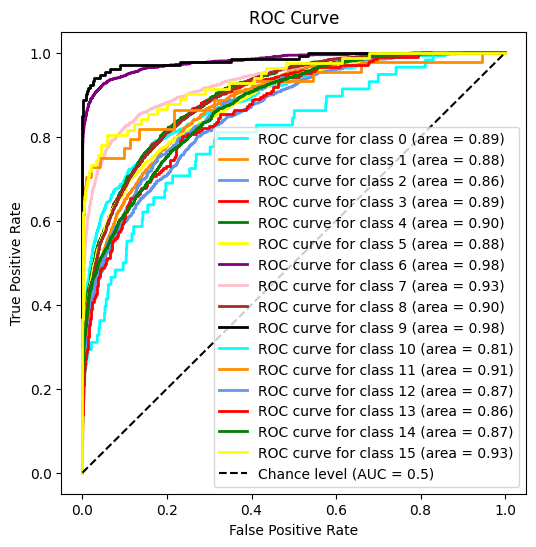

              precision    recall  f1-score   support

           0       0.65      0.40      0.50       578
           1       0.52      0.41      0.46      1042
           2       0.60      0.37      0.46       915
           3       0.58      0.41      0.48       810
           4       0.53      0.51      0.52      1049
           5       0.55      0.58      0.57      1681
           6       0.87      0.88      0.87      1692
           7       0.68      0.74      0.71      1998
           8       0.51      0.78      0.61      2796
           9       0.99      0.84      0.91       132
          10       0.86      0.10      0.18        58
          11       0.61      0.45      0.52        44
          12       0.57      0.20      0.30       355
          13       0.69      0.17      0.27       211
          14       0.56      0.49      0.52      1462
          15       0.85      0.41      0.56        82

    accuracy                           0.60     14905
   macro avg       0.66   

In [34]:
# Combine image columns to form the feature set
X_train = train_df[image_columns].values
X_test = test_df[image_columns].values

# Train and evaluate models
trained_models = train_classic(X_train, X_test, y_train, y_test, class_names=y_test_original)

#### Multimodal features

####################  Random Forest  ####################


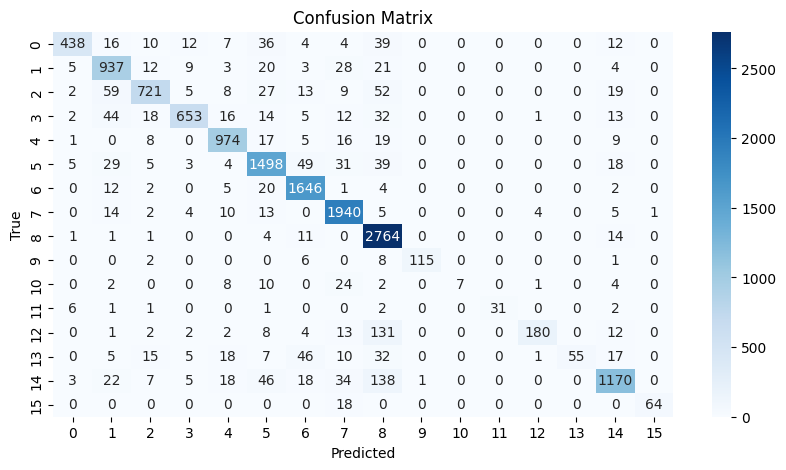

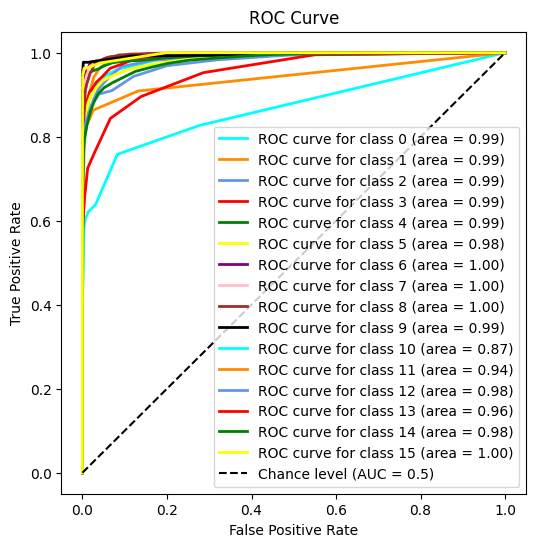

              precision    recall  f1-score   support

           0       0.95      0.76      0.84       578
           1       0.82      0.90      0.86      1042
           2       0.89      0.79      0.84       915
           3       0.94      0.81      0.87       810
           4       0.91      0.93      0.92      1049
           5       0.87      0.89      0.88      1681
           6       0.91      0.97      0.94      1692
           7       0.91      0.97      0.94      1998
           8       0.84      0.99      0.91      2796
           9       0.99      0.87      0.93       132
          10       1.00      0.12      0.22        58
          11       1.00      0.70      0.83        44
          12       0.96      0.51      0.66       355
          13       1.00      0.26      0.41       211
          14       0.90      0.80      0.85      1462
          15       0.98      0.78      0.87        82

    accuracy                           0.89     14905
   macro avg       0.93   

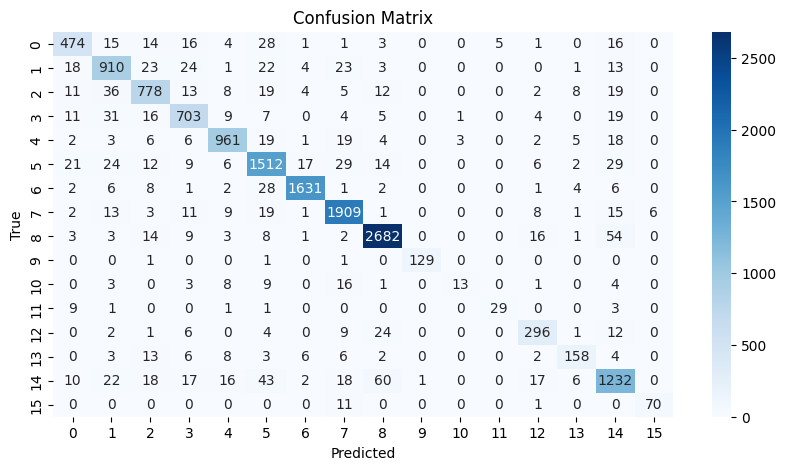

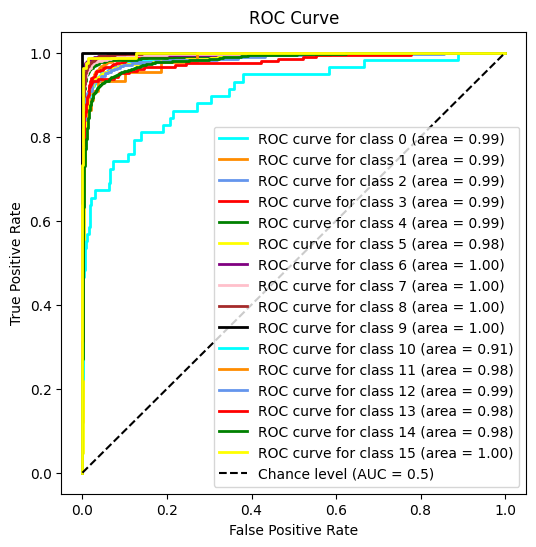

              precision    recall  f1-score   support

           0       0.84      0.82      0.83       578
           1       0.85      0.87      0.86      1042
           2       0.86      0.85      0.85       915
           3       0.85      0.87      0.86       810
           4       0.93      0.92      0.92      1049
           5       0.88      0.90      0.89      1681
           6       0.98      0.96      0.97      1692
           7       0.93      0.96      0.94      1998
           8       0.95      0.96      0.96      2796
           9       0.99      0.98      0.98       132
          10       0.76      0.22      0.35        58
          11       0.85      0.66      0.74        44
          12       0.83      0.83      0.83       355
          13       0.84      0.75      0.79       211
          14       0.85      0.84      0.85      1462
          15       0.92      0.85      0.89        82

    accuracy                           0.90     14905
   macro avg       0.88   

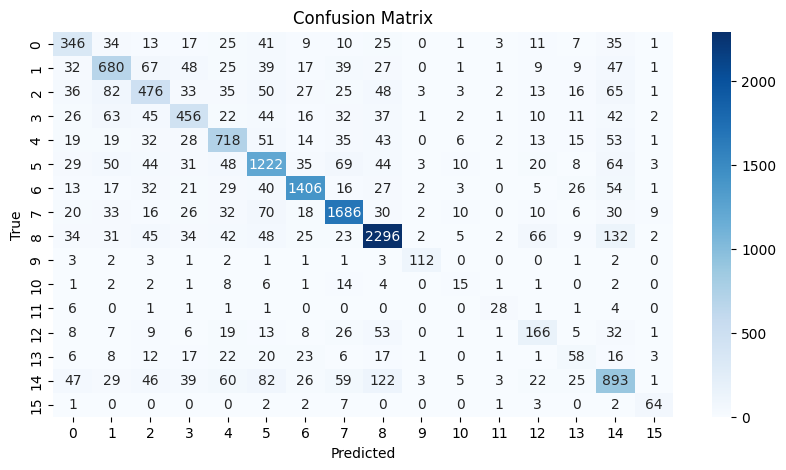

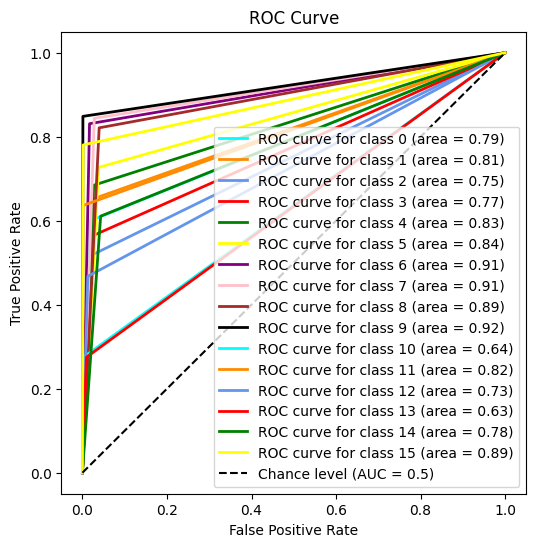

              precision    recall  f1-score   support

           0       0.55      0.60      0.57       578
           1       0.64      0.65      0.65      1042
           2       0.56      0.52      0.54       915
           3       0.60      0.56      0.58       810
           4       0.66      0.68      0.67      1049
           5       0.71      0.73      0.72      1681
           6       0.86      0.83      0.85      1692
           7       0.82      0.84      0.83      1998
           8       0.83      0.82      0.82      2796
           9       0.87      0.85      0.86       132
          10       0.24      0.26      0.25        58
          11       0.60      0.64      0.62        44
          12       0.47      0.47      0.47       355
          13       0.29      0.27      0.28       211
          14       0.61      0.61      0.61      1462
          15       0.71      0.78      0.74        82

    accuracy                           0.71     14905
   macro avg       0.63   

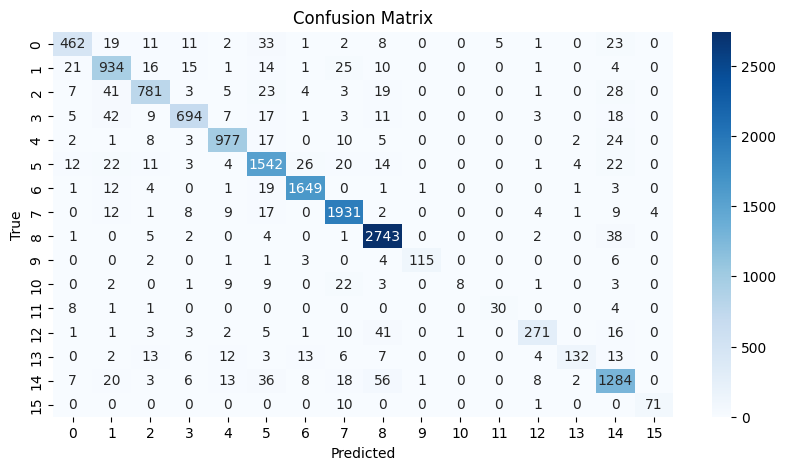

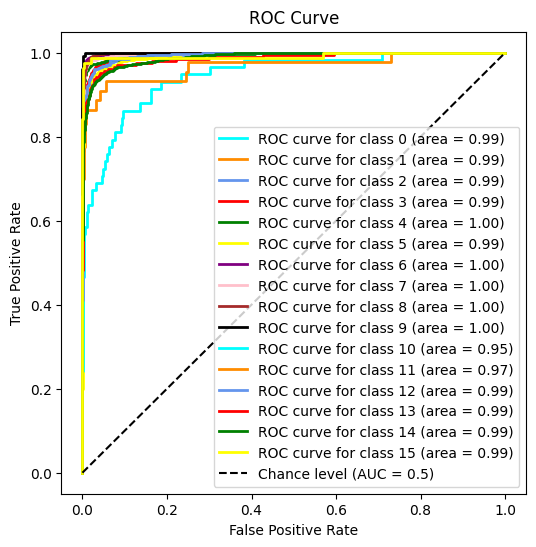

              precision    recall  f1-score   support

           0       0.88      0.80      0.84       578
           1       0.84      0.90      0.87      1042
           2       0.90      0.85      0.88       915
           3       0.92      0.86      0.89       810
           4       0.94      0.93      0.93      1049
           5       0.89      0.92      0.90      1681
           6       0.97      0.97      0.97      1692
           7       0.94      0.97      0.95      1998
           8       0.94      0.98      0.96      2796
           9       0.98      0.87      0.92       132
          10       0.89      0.14      0.24        58
          11       0.86      0.68      0.76        44
          12       0.91      0.76      0.83       355
          13       0.93      0.63      0.75       211
          14       0.86      0.88      0.87      1462
          15       0.95      0.87      0.90        82

    accuracy                           0.91     14905
   macro avg       0.91   

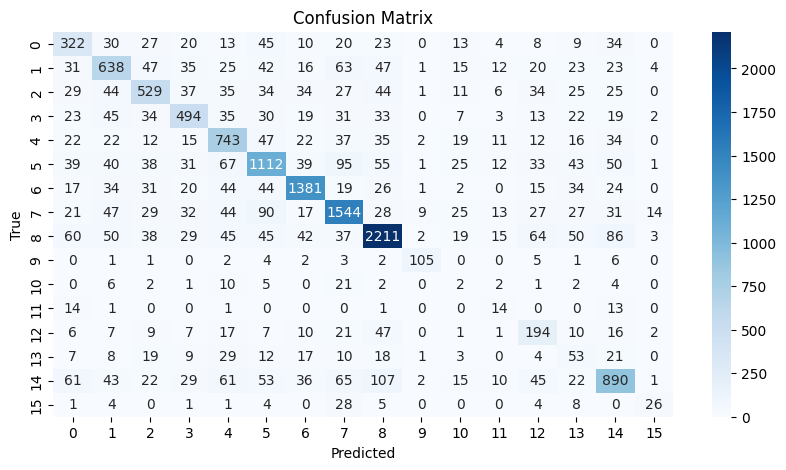

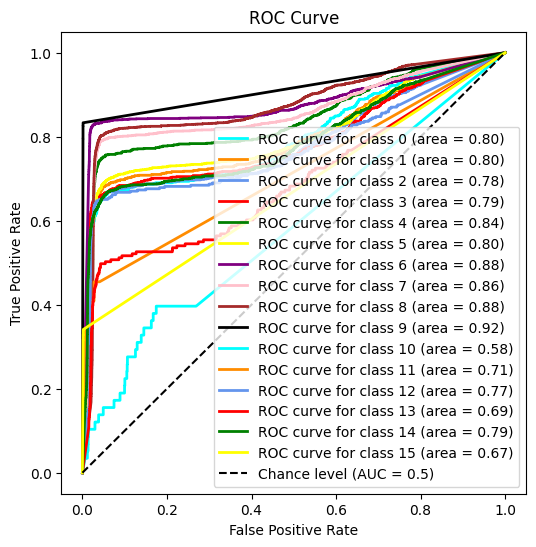

              precision    recall  f1-score   support

           0       0.49      0.56      0.52       578
           1       0.63      0.61      0.62      1042
           2       0.63      0.58      0.60       915
           3       0.65      0.61      0.63       810
           4       0.63      0.71      0.67      1049
           5       0.71      0.66      0.68      1681
           6       0.84      0.82      0.83      1692
           7       0.76      0.77      0.77      1998
           8       0.82      0.79      0.81      2796
           9       0.84      0.80      0.82       132
          10       0.01      0.03      0.02        58
          11       0.14      0.32      0.19        44
          12       0.41      0.55      0.47       355
          13       0.15      0.25      0.19       211
          14       0.70      0.61      0.65      1462
          15       0.49      0.32      0.39        82

    accuracy                           0.69     14905
   macro avg       0.56   

In [36]:
# Combine text and image columns to form the feature set
X_train = train_df[text_columns + image_columns].values
X_test = test_df[text_columns + image_columns].values

# Train and evaluate models
trained_models = train_classic(X_train, X_test, y_train, y_test, class_names=y_test_original)

**Classical ML results.**

| Features | Best model | Accuracy | Macro F1 |
|---|---|---|---|
| Text | LightGBM | 0.92 | 0.85 |
| Image | XGBoost / LightGBM | 0.59 - 0.60 | 0.53 |
| Multimodal | XGBoost / Logistic Regression | 0.90 - 0.91 | 0.84 - 0.85 |

- Text embeddings carry most of the signal: four of the five classifiers reach about 0.90 accuracy and 0.83 - 0.85 macro F1 on text alone.
- Image embeddings are much weaker for classical models, with accuracy at or below 0.60 and macro F1 at or below 0.53.
- Simply concatenating image features to text features does not help classical models. Logistic Regression and XGBoost stay around 0.90 - 0.91 accuracy, while LightGBM drops from 0.92 to 0.69 and Random Forest's macro F1 falls from 0.83 to 0.80, suggesting the high-dimensional image features add noise.

### 3.3 Multi-layer perceptron

A multi-layer perceptron (MLP) is a feed-forward neural network made of fully connected layers. The input layer receives the embedding features, one or more hidden layers learn non-linear combinations of them, and a softmax output layer produces one probability per category.

Three MLPs are trained with `train_mlp` from `src/classifiers_mlp.py`, on the image, text, and combined (early fusion) features. Each run reports a classification report and confusion matrix, and saves its test-set predictions to `results/image_results.csv`, `results/text_results.csv`, and `results/multimodal_results.csv`.

**Performance targets:**
- Multimodal model: accuracy >= 85% and F1 >= 80%.
- Text model: accuracy >= 85% and F1 >= 80%.
- Image model: accuracy >= 75% and F1 >= 70%.

#### Dataset preparation

The label encoder is fit on the training labels only and reused for the test set.

In [16]:
# Initialize LabelEncoder and fit it only on the training data
label_encoder = LabelEncoder()
label_encoder.fit(train_df[label_columns])

LabelEncoder()

#### Image model

Image embedding columns are standardized (fit on the training set only) before training, which improves convergence of the image MLP.

In [17]:
# Adding in data scaling to improve model results
from sklearn.preprocessing import StandardScaler

# Create a copy of your DataFrames
train_df_scaled = train_df.copy()
test_df_scaled = test_df.copy()

# Scale only the image embedding columns
scaler_image = StandardScaler()

# Fit on train data and transform
train_df_scaled[image_columns] = scaler_image.fit_transform(train_df[image_columns])
test_df_scaled[image_columns] = scaler_image.transform(test_df[image_columns])


In [18]:
# Create the datasets and ensure the encoder is passed to both train and test sets
train_dataset = MultimodalDataset(train_df_scaled, text_cols=None, image_cols=image_columns, label_col=label_columns[0], encoder=label_encoder, batch_size=64)
test_dataset = MultimodalDataset(test_df_scaled, text_cols=None, image_cols=image_columns, label_col=label_columns[0], encoder=label_encoder, batch_size=64)

text_input_size = None
image_input_size = len(image_columns)
output_size = label_encoder.classes_.shape[0]

Training Image Model:
Epoch 1/50
543/543 [==============================] - 22s 31ms/step - loss: 1.4121 - accuracy: 0.5913 - val_loss: 1.1418 - val_accuracy: 0.6481
Epoch 2/50
543/543 [==============================] - 17s 32ms/step - loss: 0.9027 - accuracy: 0.6962 - val_loss: 1.0735 - val_accuracy: 0.6756
Epoch 3/50
543/543 [==============================] - 18s 33ms/step - loss: 0.7241 - accuracy: 0.7345 - val_loss: 0.8789 - val_accuracy: 0.7384
Epoch 4/50
543/543 [==============================] - 19s 35ms/step - loss: 0.6107 - accuracy: 0.7707 - val_loss: 0.9601 - val_accuracy: 0.7219
Epoch 5/50
543/543 [==============================] - 21s 38ms/step - loss: 0.5553 - accuracy: 0.7832 - val_loss: 0.8299 - val_accuracy: 0.7569
Epoch 6/50
543/543 [==============================] - 18s 33ms/step - loss: 0.4809 - accuracy: 0.8095 - val_loss: 0.7668 - val_accuracy: 0.7799
Epoch 7/50
543/543 [==============================] - 25s 46ms/step - loss: 0.4284 - accuracy: 0.8240 - val_loss: 

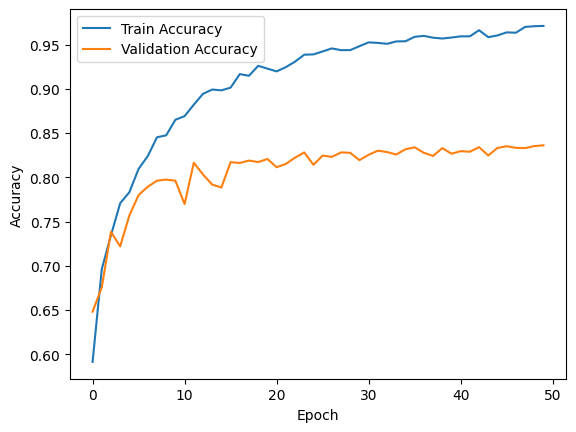

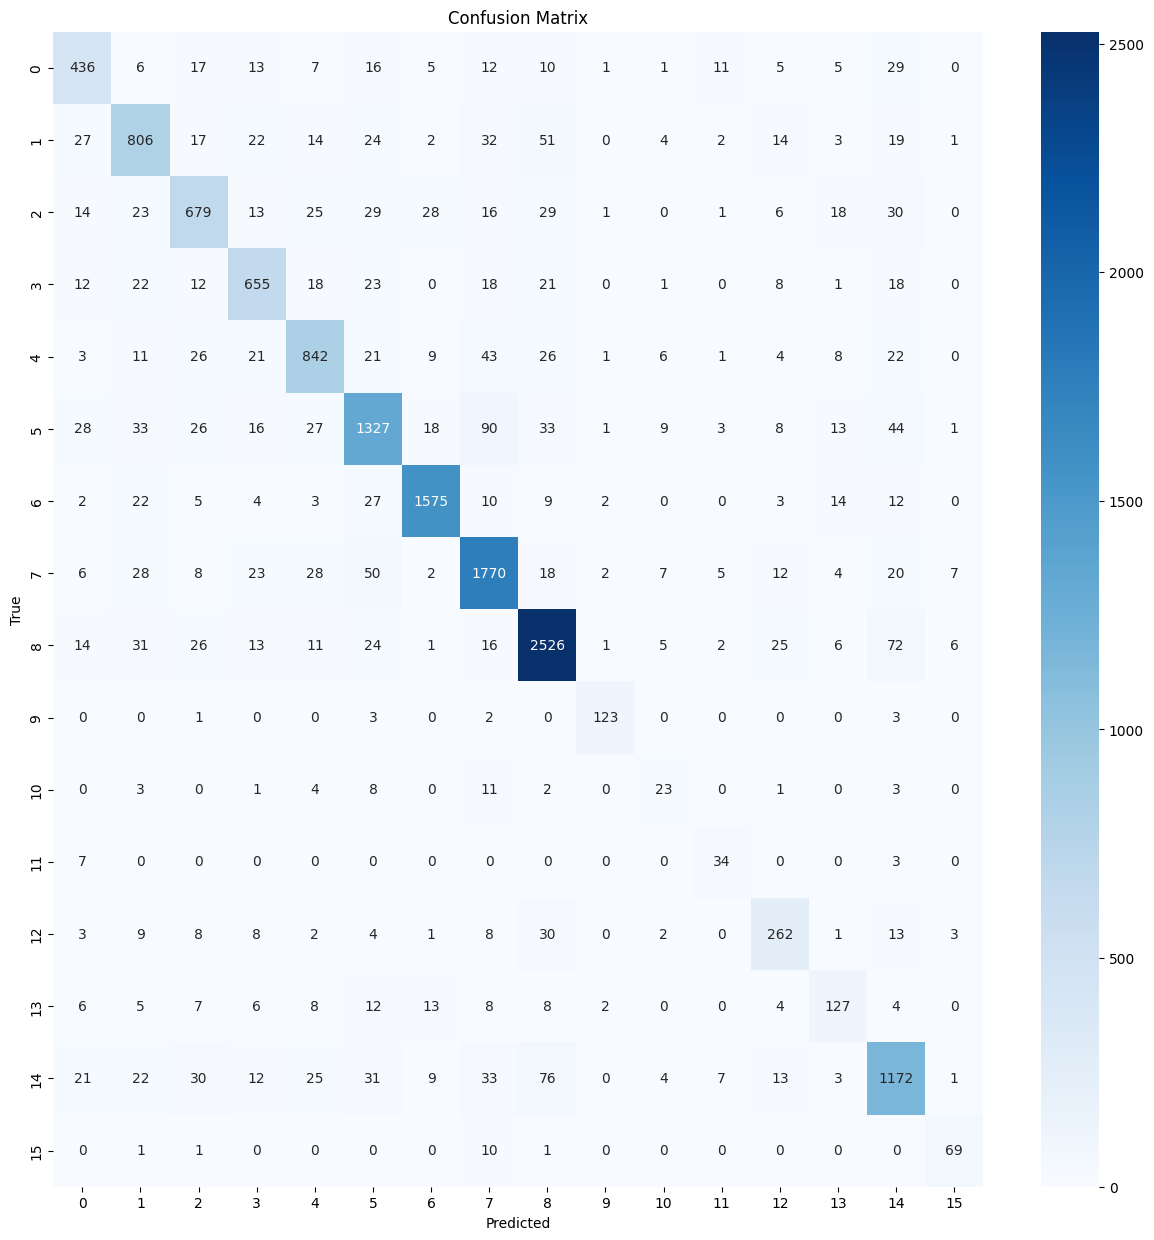

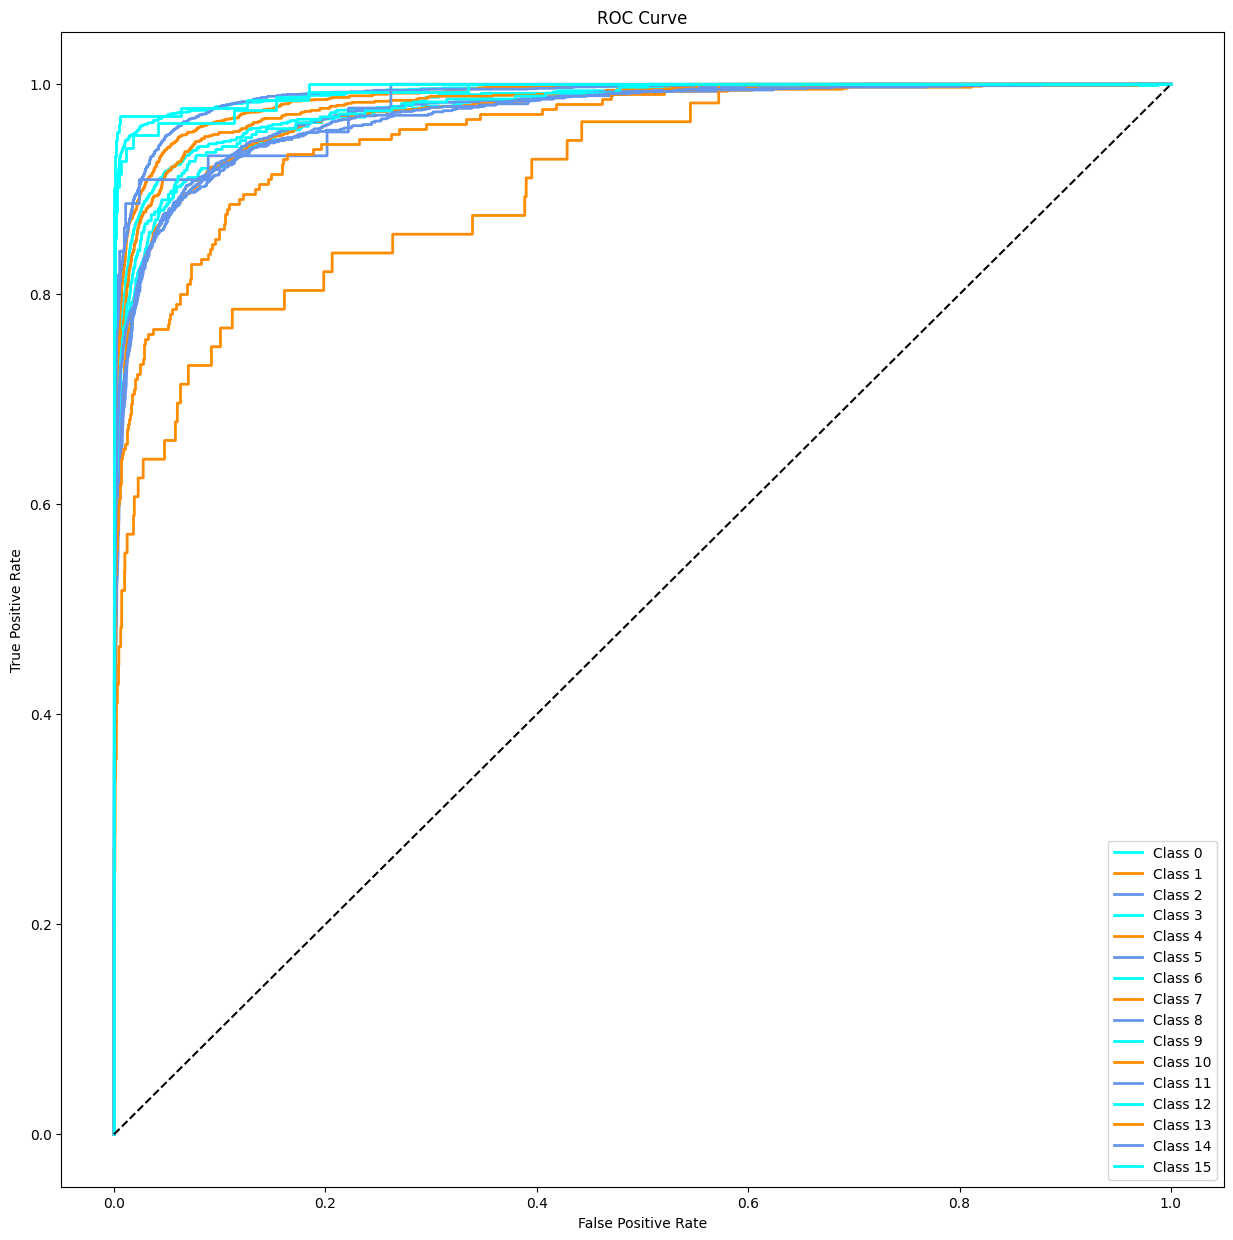

                    precision    recall  f1-score   support

      abcat0100000       0.75      0.76      0.76       574
      abcat0200000       0.79      0.78      0.78      1038
      abcat0207000       0.79      0.74      0.77       912
      abcat0300000       0.81      0.81      0.81       809
      abcat0400000       0.83      0.81      0.82      1044
      abcat0500000       0.83      0.79      0.81      1677
      abcat0700000       0.95      0.93      0.94      1688
      abcat0800000       0.85      0.89      0.87      1990
      abcat0900000       0.89      0.91      0.90      2779
          cat09000       0.92      0.93      0.92       132
pcmcat128500050004       0.37      0.41      0.39        56
pcmcat139900050002       0.52      0.77      0.62        44
pcmcat242800050021       0.72      0.74      0.73       354
pcmcat252700050006       0.63      0.60      0.62       210
pcmcat312300050015       0.80      0.80      0.80      1459
pcmcat332000050000       0.78      0.84

In [19]:
# Train the model
print("Training Image Model:")
model, accuracy, f1, auc = train_mlp(train_dataset, test_dataset,
            text_input_size=text_input_size, 
            image_input_size=image_input_size, 
            output_size=output_size, 
            num_epochs=50,
            report=True, 
            lr=0.001, 
            set_weights=True, 
            adam=True, 
            p=0.2,  
            seed=42, 
            patience=10)

#### Text model

In [18]:
# Create the datasets and ensure the encoder is passed to both train and test sets
train_dataset = MultimodalDataset(train_df, text_cols=text_columns, image_cols=None, label_col=label_columns, encoder=label_encoder)
test_dataset = MultimodalDataset(test_df, text_cols=text_columns, image_cols=None, label_col=label_columns, encoder=label_encoder)

text_input_size = len(text_columns)
image_input_size = None
output_size = label_encoder.classes_.shape[0]

Training Text Model:


Epoch 1/50
1086/1086 [==============================] - 28s 17ms/step - loss: 0.9563 - accuracy: 0.7266 - val_loss: 0.5255 - val_accuracy: 0.8536
Epoch 2/50
1086/1086 [==============================] - 17s 16ms/step - loss: 0.5904 - accuracy: 0.8260 - val_loss: 0.4958 - val_accuracy: 0.8577
Epoch 3/50
1086/1086 [==============================] - 11s 11ms/step - loss: 0.4934 - accuracy: 0.8451 - val_loss: 0.3867 - val_accuracy: 0.8938
Epoch 4/50
1086/1086 [==============================] - 11s 10ms/step - loss: 0.4301 - accuracy: 0.8628 - val_loss: 0.3869 - val_accuracy: 0.8929
Epoch 5/50
1086/1086 [==============================] - 8s 7ms/step - loss: 0.3845 - accuracy: 0.8734 - val_loss: 0.4428 - val_accuracy: 0.8690
Epoch 6/50
1086/1086 [==============================] - 10s 9ms/step - loss: 0.3508 - accuracy: 0.8809 - val_loss: 0.3455 - val_accuracy: 0.9027
Epoch 7/50
1086/1086 [==============================] - 11s 10ms/step - loss: 0.3086 - accuracy: 0.8918 - val_loss: 0.3448 - va

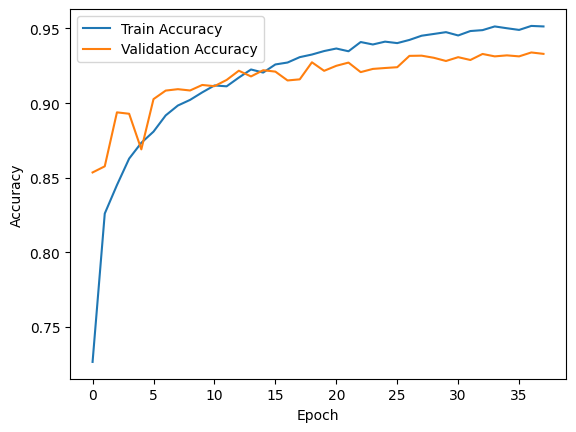

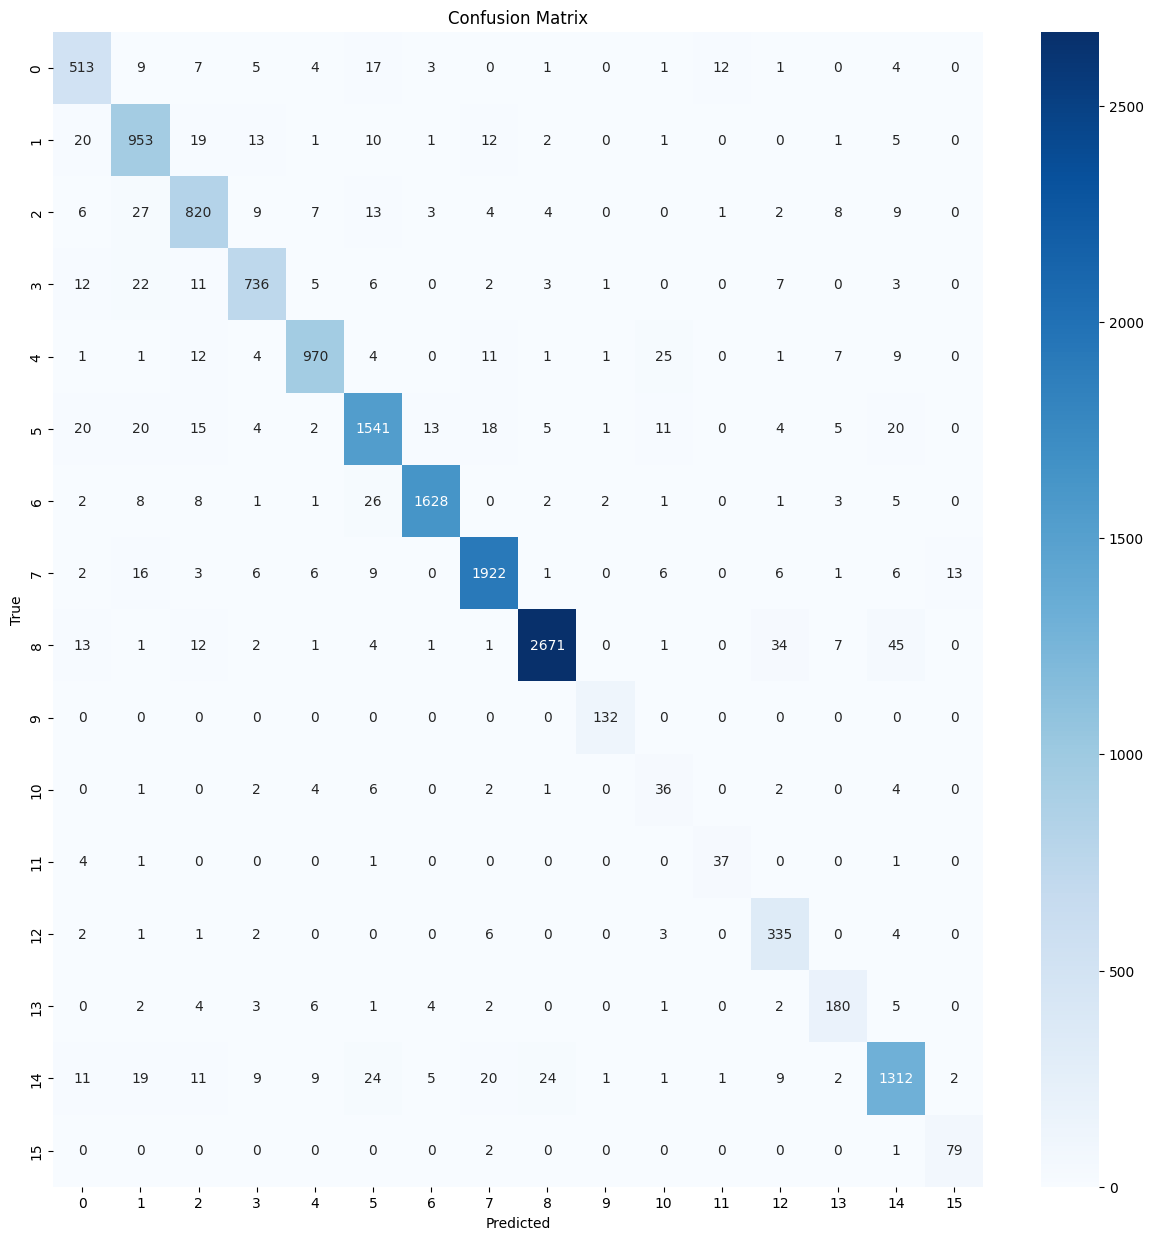

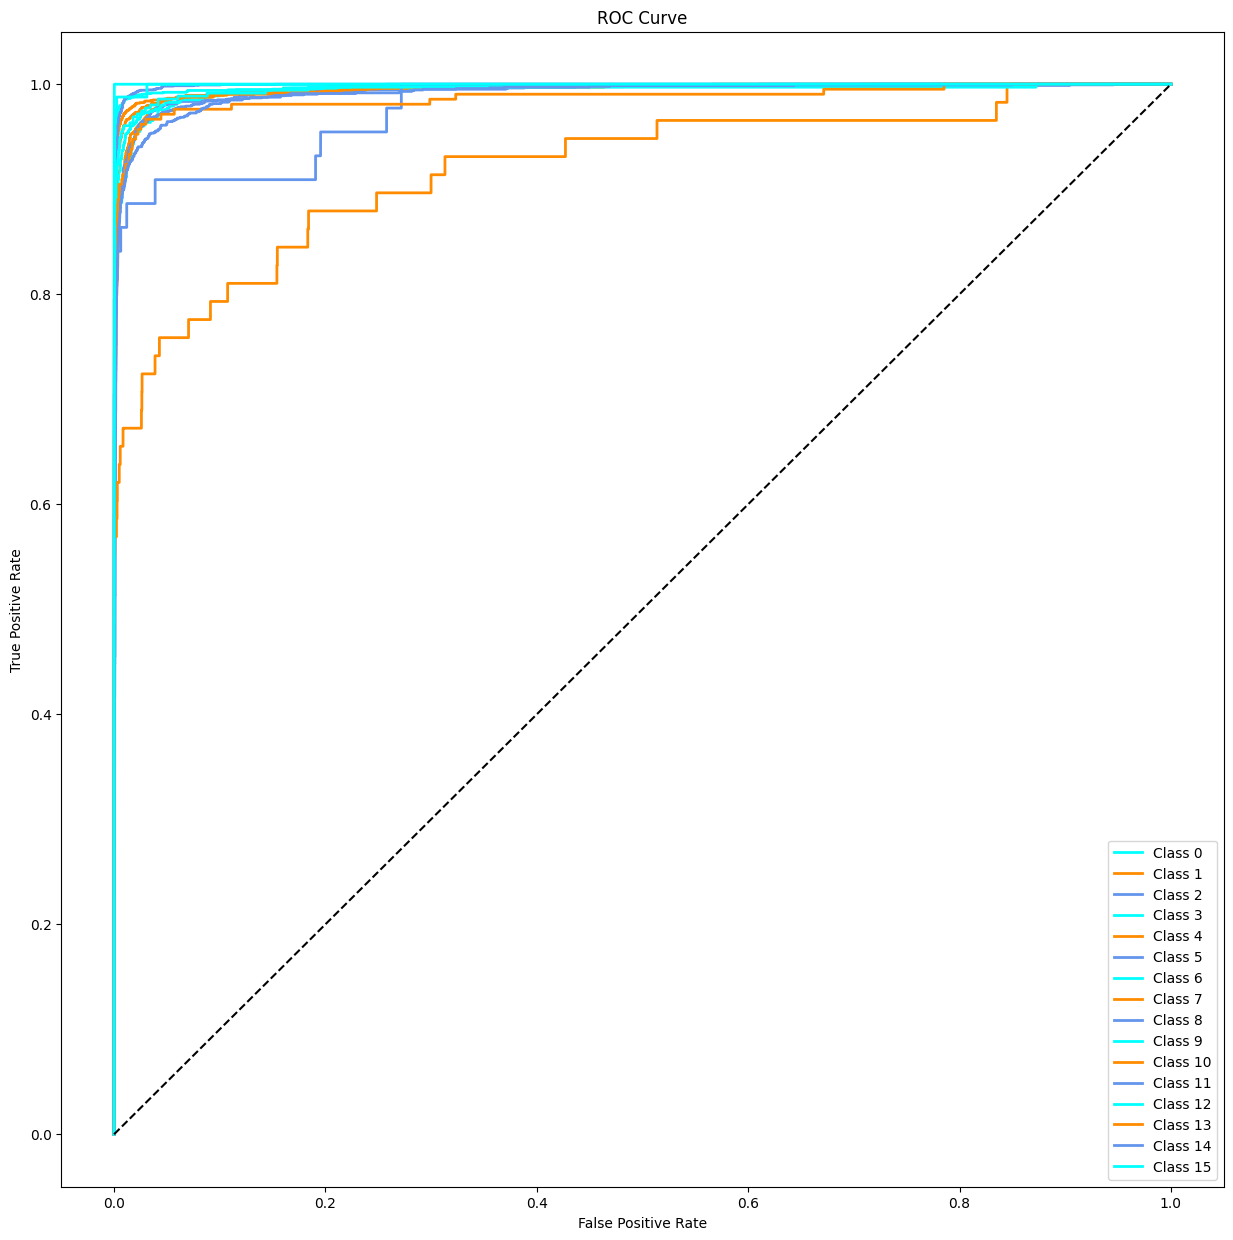

                    precision    recall  f1-score   support

      abcat0100000       0.85      0.89      0.87       577
      abcat0200000       0.88      0.92      0.90      1038
      abcat0207000       0.89      0.90      0.89       913
      abcat0300000       0.92      0.91      0.92       808
      abcat0400000       0.95      0.93      0.94      1047
      abcat0500000       0.93      0.92      0.92      1679
      abcat0700000       0.98      0.96      0.97      1688
      abcat0800000       0.96      0.96      0.96      1997
      abcat0900000       0.98      0.96      0.97      2793
          cat09000       0.96      1.00      0.98       132
pcmcat128500050004       0.41      0.62      0.50        58
pcmcat139900050002       0.73      0.84      0.78        44
pcmcat242800050021       0.83      0.95      0.88       354
pcmcat252700050006       0.84      0.86      0.85       210
pcmcat312300050015       0.92      0.90      0.91      1460
pcmcat332000050000       0.84      0.96

(<keras.src.engine.functional.Functional at 0x1d19d538390>,
 0.9317876344086021,
 0.8834851873700345,
 0.9895682563354061)

In [19]:
# Train the model
print("Training Text Model:")
train_mlp(train_dataset, test_dataset,
            text_input_size=text_input_size, 
            image_input_size=image_input_size, 
            output_size=output_size, 
            num_epochs=50,
            report=True, 
            lr=0.001, 
            set_weights=True, 
            adam=True, 
            p=0.2,  
            seed=42, 
            patience=10)

#### Early fusion model

Text embeddings and standardized image embeddings are concatenated into a single input vector. This model uses a lower learning rate (0.0002), higher dropout (0.3), and longer patience for early stopping than the single-modality models.

In [19]:
# Create the datasets and ensure the encoder is passed to both train and test sets
train_dataset = MultimodalDataset(train_df_scaled, text_cols=text_columns, image_cols=image_columns, label_col=label_columns, encoder=label_encoder)
test_dataset = MultimodalDataset(test_df_scaled, text_cols=text_columns, image_cols=image_columns, label_col=label_columns, encoder=label_encoder)

text_input_size = len(text_columns)
image_input_size = len(image_columns)
output_size = label_encoder.classes_.shape[0]

Training Early Fusion Model:
Epoch 1/100
1086/1086 [==============================] - 25s 19ms/step - loss: 2.3637 - accuracy: 0.2688 - val_loss: 1.9517 - val_accuracy: 0.5484
Epoch 2/100
1086/1086 [==============================] - 20s 18ms/step - loss: 1.5381 - accuracy: 0.5073 - val_loss: 1.5961 - val_accuracy: 0.7002
Epoch 3/100
1086/1086 [==============================] - 18s 17ms/step - loss: 1.1840 - accuracy: 0.6210 - val_loss: 1.4948 - val_accuracy: 0.7562
Epoch 4/100
1086/1086 [==============================] - 18s 17ms/step - loss: 0.9746 - accuracy: 0.6826 - val_loss: 1.2909 - val_accuracy: 0.7909
Epoch 5/100
1086/1086 [==============================] - 17s 16ms/step - loss: 0.8207 - accuracy: 0.7263 - val_loss: 1.2852 - val_accuracy: 0.7981
Epoch 6/100
1086/1086 [==============================] - 13s 12ms/step - loss: 0.7272 - accuracy: 0.7501 - val_loss: 1.1728 - val_accuracy: 0.8279
Epoch 7/100
1086/1086 [==============================] - 13s 12ms/step - loss: 0.6547 - a

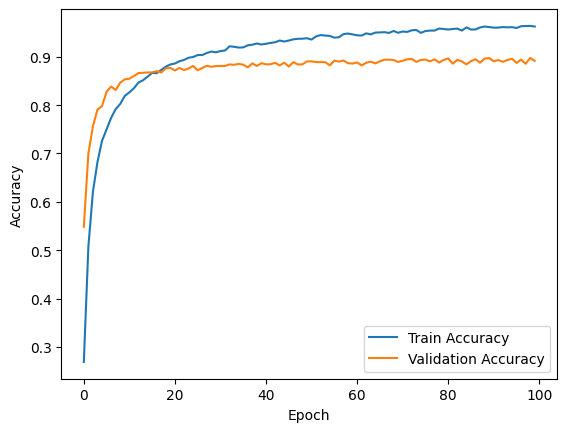

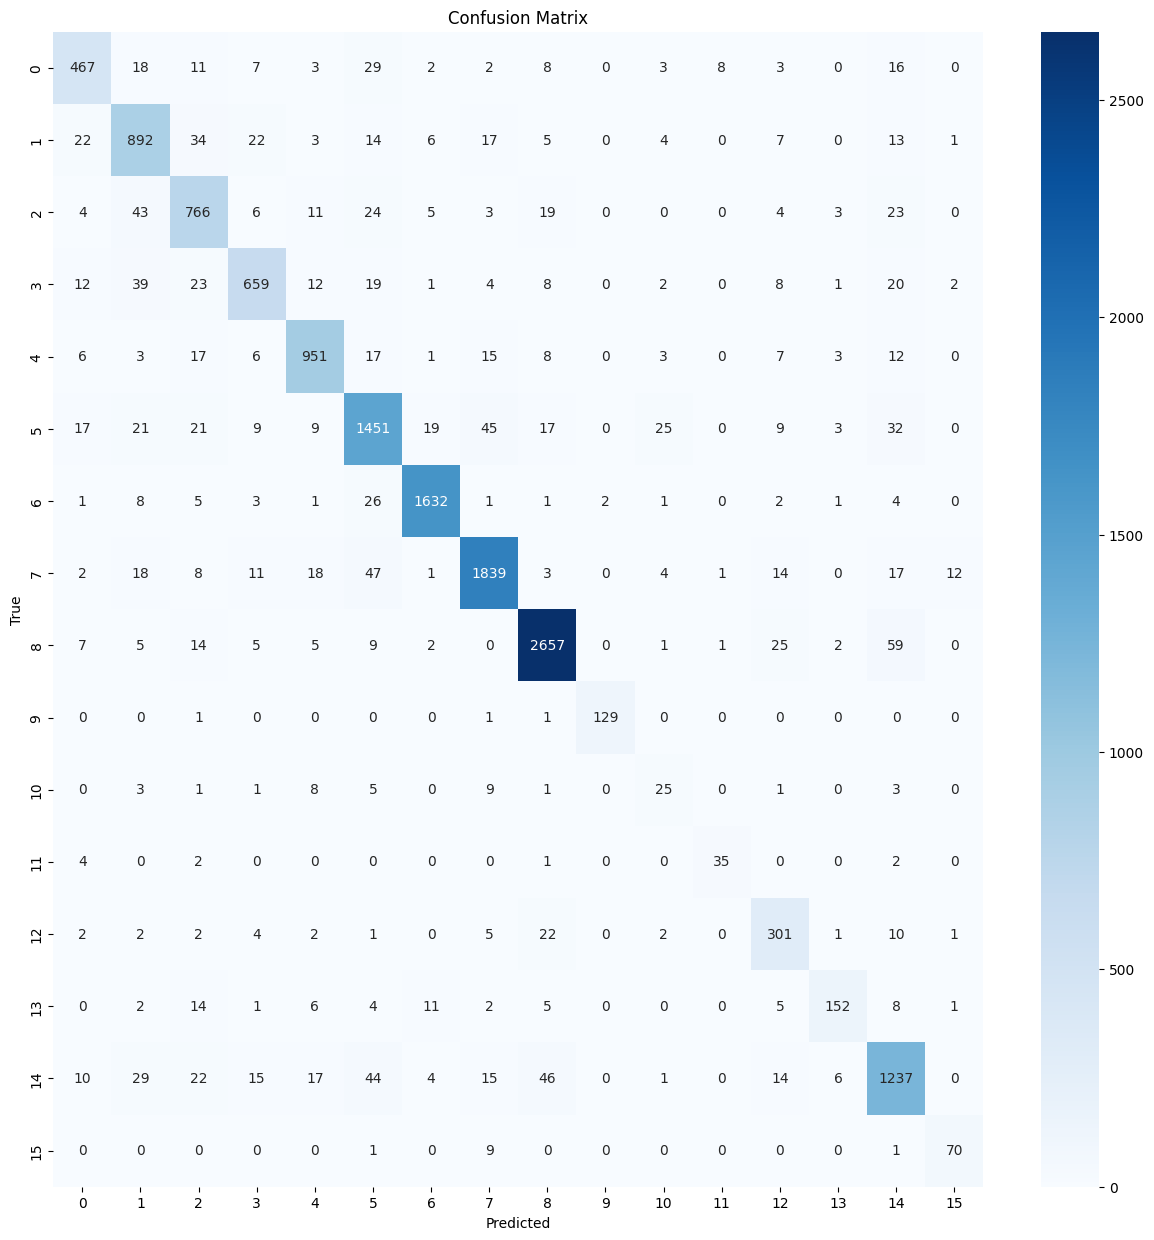

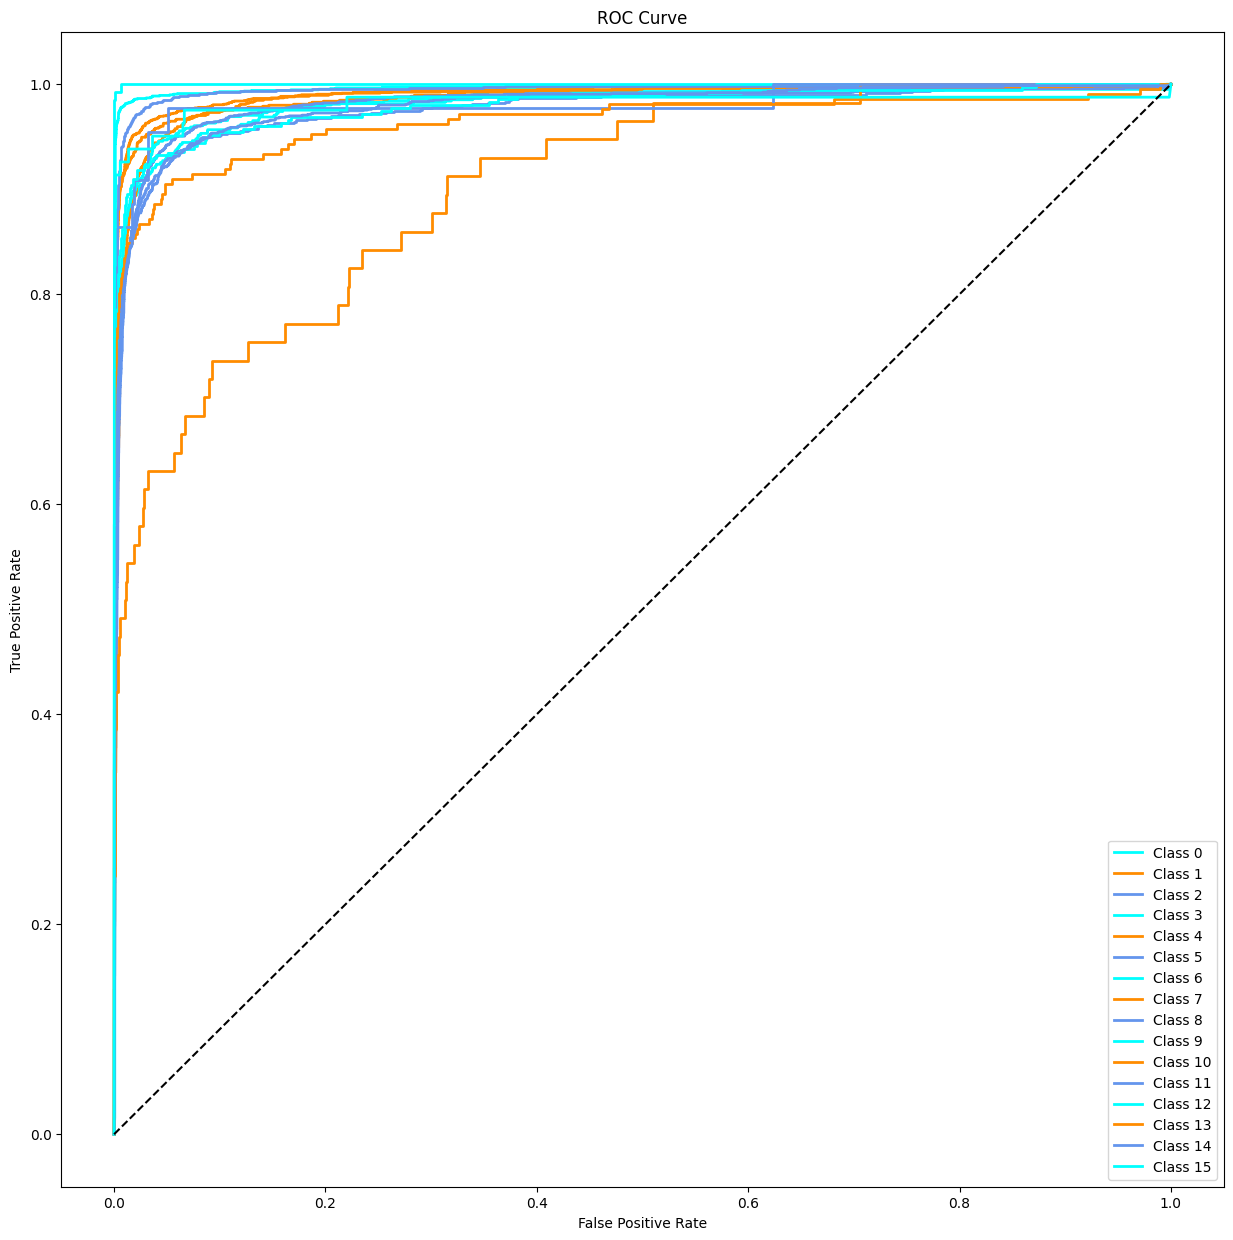

                    precision    recall  f1-score   support

      abcat0100000       0.84      0.81      0.83       577
      abcat0200000       0.82      0.86      0.84      1040
      abcat0207000       0.81      0.84      0.83       911
      abcat0300000       0.88      0.81      0.85       810
      abcat0400000       0.91      0.91      0.91      1049
      abcat0500000       0.86      0.86      0.86      1678
      abcat0700000       0.97      0.97      0.97      1688
      abcat0800000       0.93      0.92      0.93      1995
      abcat0900000       0.95      0.95      0.95      2792
          cat09000       0.98      0.98      0.98       132
pcmcat128500050004       0.35      0.44      0.39        57
pcmcat139900050002       0.78      0.80      0.79        44
pcmcat242800050021       0.75      0.85      0.80       355
pcmcat252700050006       0.88      0.72      0.79       211
pcmcat312300050015       0.85      0.85      0.85      1460
pcmcat332000050000       0.80      0.86

(<keras.src.engine.functional.Functional at 0x196edd55bd0>,
 0.8913306451612903,
 0.8365588647291584,
 0.9795402018560115)

In [20]:
# Train the model
print("Training Early Fusion Model:")
train_mlp(train_dataset, test_dataset,
            text_input_size=text_input_size, 
            image_input_size=image_input_size, 
            output_size=output_size, 
            num_epochs=100,
            report=True, 
            lr=0.0002, 
            set_weights=True, 
            adam=True, 
            p=0.3,  
            seed=42, 
            patience=40)

### 3.4 Evaluation questions

- Is the loss function and set of metrics appropriate for a multi-class problem?
- How does each model perform per class, and is it overfitting or underfitting?
- What could be done to improve it?
- Does the fusion model outperform the individual models, and why?

**Loss and metrics.** The MLP uses a softmax output with categorical cross-entropy, the standard choice for single-label multi-class classification. Because category sizes range from about 40 to over 2,700 test samples, accuracy alone would be dominated by the largest classes. Macro F1 and per-class reports are therefore used alongside accuracy, and balanced class weights are applied during training (`set_weights=True`).

**Per-class performance.** Most categories are classified well, but the smallest ones lag behind. The weakest class, `pcmcat128500050004` (about 57 test samples), reaches an F1 of only 0.39 for the image model, 0.50 for the text model, and 0.39 for the fusion model.

**Overfitting.** All three MLPs show some degree of overfitting, most clearly the image model. Its training accuracy rises to 0.97 while validation accuracy plateaus around 0.83 - 0.84, and validation loss bottoms out around 0.71 near epoch 12 before climbing to about 0.95. The fusion model shows the same pattern (training accuracy about 0.96, validation accuracy about 0.89, rising validation loss). The text model generalizes best, with validation loss stable around 0.29 - 0.33.

**Possible improvements.** Stronger regularization (more dropout, weight decay), early stopping on validation loss rather than validation accuracy, data augmentation or oversampling for minority classes, and a tuned architecture are the most direct options. Better image embeddings (larger backbones or CLIP) would also address the weakest modality.

**Fusion vs. individual models.** The early fusion MLP (accuracy 0.89, macro F1 0.84) clearly beats the image MLP (0.84, 0.77) but does not beat the text MLP (0.93, 0.88). With early fusion, the network has to learn from the noisier, higher-dimensional image features at the same time as the text features, which makes it overfit sooner. Late fusion, or weighting the modalities, would be a better way to use the image signal without diluting the text signal.

**Performance targets.** All three MLPs meet their targets:

| Model | Accuracy | Macro F1 | AUC | Target (Acc / F1) |
|---|---|---|---|---|
| Image MLP | 0.84 | 0.77 | - | 0.75 / 0.70 |
| Text MLP | 0.93 | 0.88 | 0.99 | 0.85 / 0.80 |
| Early fusion MLP | 0.89 | 0.84 | 0.98 | 0.85 / 0.80 |

## 4. Further experiments

The models above cover only a small part of the possible design space. Directions for further improvement include:
1. Trying other pre-trained text and image embedding models.
2. Using closed-source embedding models, such as OpenAI's embeddings API.
3. Adding data augmentation or additional regularization.
4. Running a systematic architecture and hyperparameter search with [KerasTuner](https://keras.io/api/keras_tuner/).
5. Weighing the trade-off between performance and computational cost when choosing a model for production.

**Summary.**

- Text embeddings (`all-MiniLM-L6-v2`) are the most informative features for this task. The text MLP is the best model overall (accuracy 0.93, macro F1 0.88), followed by LightGBM on text features (0.92, 0.85).
- Image embeddings (`ConvNextV2-tiny`) are far weaker for classical models (accuracy at most 0.60), but an MLP on standardized image features reaches 0.84 accuracy.
- Early fusion improves substantially on image-only models but does not surpass text-only models, and it overfits more readily.
- For deployment, the text MLP offers the best accuracy at the lowest cost, since it needs no image processing. Late fusion and stronger image backbones are the most promising ways to get additional value from the images.